# RKEM-Net: Recurrent Kernel Episodic Memory Network
### MS thesis implementation: unsupervised continual object learning from video without catastrophic forgetting

**Thesis:** *RKEM-Net: A Recurrent Kernel Episodic Memory Network for Unsupervised Continual Object Learning*

**Author:** Sana Akhtar Naseer, University of Central Punjab, 2023.

**Problem.** How can an unsupervised system keep discovering new visual objects, preserve what it already knows,
avoid prototype interference, and stay within a fixed memory budget?

This single notebook reproduces **every result in the thesis** under one protocol. Object IDs are **never** used by
any learning step; they only build the stage schedule and score the results.

#### Model versions and their names in the thesis

| Code name | Thesis name | Content | Thesis sections |
|---|---|---|---|
| **v1** | Baseline model | Growing Gaussian-kernel prototypes, optional stability and replay | 3.2, Chapter 4 |
| **v2** | Intermediate model | + label-free whitening (VPL), two-timescale recurrent state (RKLL), anchors, episodic concepts | 4.4, 4.5.1 |
| **v3** | **RKEM-Net** (proposed) | + episode-level routing, STM/LTM dual memory, sleep consolidation, fixed memory budget | 3.3–3.10, 4.1–4.6 |
| **v3.1** | RKEM-Net with boundary detector | + label-free episode boundary detector (c = 1.0, selected on validation) | 3.11, 4.7 |

#### Notebook map

| Section | What it does | Thesis |
|---|---|---|
| 1 | Setup and run switches | – |
| 2–4 | Core layers, RKEM-Net v3/v3.1, experiment runner | Chapter 3 |
| 5–7 | Simulator, figures/statistics, unit checks | 3.13.9 |
| 8 (Part A) | Simulator validation of every component (25 paired runs) | 4.11 |
| 9 | CORe50 data pipeline and frozen ResNet18 features | 3.13.1–3.13.3 |
| 10 (Part B1) | *Optional:* earlier experiment features (not used in the thesis; off by default) | – |
| 11 (Part B2) | **Main CORe50 protocol**: v1, v2, v3, v3.1, ablations, budget, references | 4.1–4.7, 4.10 |
| 13a–13d | Published baselines with official code: GDM (and STAM, off) | 4.8 |
| 13e | STAM runtime measurement | 4.9 |
| 12 | Package all outputs into `RKEM_v3_evidence.zip` | Annexure C–D |

#### How to run
1. Kaggle notebook, **GPU T4**, **Internet on** (GDM/STAM code is cloned from the authors' GitHub repositories).
2. Add the **CORe50** dataset (128×128 version) as input.
3. **Save Version → Save & Run All (Commit)**. Total time: about 1–1.5 hours (STAM timing alone: up to 30 minutes).
4. All results are written to `/kaggle/working/rkem_v3/` and packed into `RKEM_v3_evidence.zip`.


## 1. Why v1 plateaued (diagnosis from the measured v1 outputs)

| # | Issue | Evidence | Fix |
|---|---|---|---|
| 1 | Raw ResNet18 features are all-positive, so cosine similarities are uniformly high ("hubness"), and the plug adapters are hard to separate | Exp 3–6 mean ARI ≈ 0.25–0.28; supervised 1-NN on group 2 = **0.547** | Label-free whitening (VPL) |
| 2 | Per-group ARI cannot see old objects being absorbed by new prototypes | Forgetting ≈ 0.005 in Exp 1–2 | Metrics on **all seen objects**; R-matrices; retention matrix |
| 3 | Prototypes are never consolidated into objects; Exp 6 union-find chaining merged everything | Exp 6 middle-group associated ARI = **0.000** | Average-linkage concepts; frozen old concepts |
| 4 | 24 frames out of ~300 breaks temporal continuity | Shuffled controls ≥ ordered (Exp 2: 0.469 vs 0.231) | Stride 5; gated recurrent state with automatic boundary detection |
| 5 | Exp 1 compared ~250 raw nodes with 19 temporal nodes | Exp 1 node counts | Same label-free stage-1 node budget for every variant |
| 6 | Hyperparameters were revised over six experiments on the same test sessions (9, 10) | — | Tuning on **validation session 11** only; official test sessions **3, 7, 10** |
| 7 | Replay was applied as a block after each stage | Replay hurt the intermediate group | Interleaved generative replay (ablation) |
| 8 | Seeds only reorder the same recordings | — | Paired Wilcoxon tests; independent datasets in Part A |

## 2. RKEM-Net v3 architecture

```
frames ─► [1] VPL  frozen encoder (ResNet18 / ResNet50 / DINOv2) ─► L2 ─► whitening (fit on unlabeled
                   stage-1 frames, then FROZEN)                                          ─► z_t
                        │
          [2] RKLL kernel gate g_t = 1[k(z_t, f_{t-1}) ≥ β]   (reset ⇒ new EPISODE e)
                   fast state f_t (view) + slow state s_t (episode identity)
                   h_t = [√(1-ρ) f_t, √ρ s_t]
                        │
          [3] Episode routing (anti-interference gate), every `block` frames:
                   evidence(c) = (1-w)·mean_t max_j k(h_t, p_cj) + w·max_k k(d_e, key_ck)
                   d_e = running mean of h over the episode
                   ┌ best is LTM and evidence ≥ τ_match and margin ≥ δ → update LTM concept
                   ├ best is STM and evidence ≥ τ_stm                  → join that STM candidate
                   └ otherwise                                          → episode's OWN STM candidate
                        │
          [4] Dual episodic memory
                   STM: plastic candidates (prototypes + episode keys)
                   LTM: consolidated concepts, η_j = η0/(1+λn_j), elastic anchors
                        │   "sleep" after every stage
          [5] Consolidation and budget
                   STM → join an LTM concept (strict, mean affinity ≥ θ_join)
                   STM ↔ STM average-linkage grouping (θ_merge) — no chaining
                   promote when supported by ≥ 2 episodes; refresh anchors
                   budget B: merge closest prototypes inside a concept, then prune weakest STM
                        │
output: concept ID = causal combination of frame evidence and episode evidence
```

**Requirement → mechanism**

| Requirement | Mechanism | Ablation that tests it |
|---|---|---|
| Discover new objects without labels | STM candidates → consolidation → promotion | — (all variants) |
| Preserve old knowledge | LTM written only on confident matches; anchors; frozen concepts | V3c (no STM: ambiguous evidence written into LTM) |
| Avoid prototype interference | Episode-level routing + margin gate | V3a (frame-level routing), V3b (no margin) |
| Use temporal/episodic structure | Episode keys and descriptors | V3d (no episode keys), V3f (shuffled frames) |
| Limited memory | Fixed prototype budget, bounded keys | V3e (unlimited) + memory-budget curve |
| Unknown recording boundaries | RKLL gate detects episodes | V3g (task-free stream) |

## 2b. v3.1 update: label-free episode boundaries for task-free streams

**What v3.1 adds.** v3 needs recording boundaries; without them it collapses (CORe50 ten_categories task-free AUC 0.265).
v3.1 detects episode boundaries itself. `GatedRecurrentKernelState.calibrate_boundary` runs the fast state over **one
concatenated, unlabeled stage-1 stream**, records `s_t = k(z_t, f_{t-1})`, and sets the gate threshold to
`median(s) - c * 1.4826 * MAD(s)`. No labels and no recording metadata are used.

**How c was chosen (validation only).** A first version used `c = 4`, chosen on the simulator. On CORe50 it detected
1 of 14 object switches: real switches have gate similarity 0.70–0.78, ordinary steps 0.87–0.94, and `c = 4` put the
threshold at 0.65, below every switch. The signal itself separates switches well (ROC AUC 0.985 six_objects,
0.998 ten_categories, validation session 11), so only `c` was wrong. `c` was re-selected on **CORe50 validation
session 11** (grid 0.5–4, task-free, seeds 11/22/33): `c = 1.0` was best (mean selection score 0.570 vs 0.177 for the fixed v3 gate).
`c = 1.0` is also best on simulator development validation. Test sessions were used once, afterwards.

**Test result (sessions 3, 7, 10; 5 orders; same features as the v3 run):**

| | v3 task-free | **v3.1 task-free** | v3, boundaries given |
|---|---|---|---|
| ten_categories AUC_matched | 0.265 | **0.558** (5/5 runs better) | 0.642 |
| ten_categories ARI (seen) | 0.006 | **0.861** | 0.891 |
| ten_categories final ACC | 0.129 | **0.781** | 0.819 |
| six_objects AUC_matched | 0.304 | **0.437** (5/5 runs better) | 0.490 |
| six_objects ARI (seen) | 0.016 | **0.251** | 0.305 |

Simulator (25 runs): task-free AUC 0.329 → 0.486.

**Use it only when boundaries are unknown.** When true recording boundaries are given, the same threshold also splits
recordings (variant `V31 … inside given recordings`): AUC −0.073 (six_objects) and −0.083 (ten_categories). The
recommended configuration is therefore v3 when boundary metadata exists and v3.1 (`V31g`) when it does not.
With n = 5 the smallest Wilcoxon p is 0.0625, so CORe50 gains are stated as "better in 5 of 5 runs".


In [1]:
# ============================================================
# RKEM-Net | Section 1: Setup and run switches
# ============================================================

import os, sys, json, time, random, platform, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220)

RUN_SYNTHETIC = True          # Part A  (~10 min on CPU with SYNTHETIC_FULL)
SYNTHETIC_FULL = True         # 5 datasets x 5 orders; False = 2 x 3 (quick check, ~2 min)
RUN_LEGACY_CACHE = False      # Part B1: optional, not used in the thesis (needs the old experiment cache)
RUN_CORE50 = True             # Part B2 (skipped automatically if CORe50 is absent)

ON_KAGGLE = Path('/kaggle/working').exists()
OUT_ROOT = Path(os.environ.get('RKEM_V2_OUT',
                '/kaggle/working/rkem_v3' if ON_KAGGLE else './rkem_v3_outputs'))
OUT_ROOT.mkdir(parents=True, exist_ok=True)
CORE50_SEARCH = os.environ.get('RKEM_CORE50_SEARCH', '/kaggle/input').split(os.pathsep)
LEGACY_SEARCH = os.environ.get('RKEM_LEGACY_SEARCH',
                '/kaggle/working/rkem_core50_evidence' + os.pathsep + '/kaggle/input').split(os.pathsep)
V1_REF, V2_REF, V3_REF = 'A* v1 Baseline (tuned budget)', 'F  RKEM-Net v2 (full)', 'V3  RKEM-Net v3 (full)'

print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| pandas', pd.__version__,
      '| platform', platform.platform())
print('Outputs ->', OUT_ROOT.resolve())

Python 3.13.16 | NumPy 2.1.3 | pandas 2.3.3 | platform Linux-6.18.55+-x86_64-with-glibc2.39
Outputs -> /kaggle/working/rkem_v3


In [2]:
# ============================================================
# RKEM-Net | Section 2: Core layers (VPL, RKLL, v2 prototype layer + EMCL, metrics)
# ============================================================
# =============================================================================
# RKEM-Net v2 — core library (label-free continual object learning)
#   VPL  : frozen encoder features + label-free centering / regularised whitening
#   RKLL : gated recurrent kernel state with automatic episode-boundary detection
#   EMCL : maturity-tightened receptive fields, anchor consolidation,
#          episodic co-activation concept memory, optional generative replay
# Object IDs are NEVER used by any learning step; they are used only to build
# the stage schedule and to score the model afterwards.
# =============================================================================
import numpy as np
from scipy.optimize import linear_sum_assignment
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform


def l2n(X, eps=1e-12):
    X = np.asarray(X, dtype=np.float32)
    if X.ndim == 1:
        return X / max(float(np.linalg.norm(X)), eps)
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), eps)


# -----------------------------------------------------------------------------
# 1. VPL — Visual Perception Layer (post-encoder, label-free)
# -----------------------------------------------------------------------------
class LabelFreeVPL:
    """Fitted ONCE on unlabeled stage-1 training features, then frozen.

    mode='none'   : L2 normalisation only (= original RKEM-Net v1 input)
    mode='center' : subtract stage-1 mean, then L2  (removes the shared
                    positive component of ReLU/GAP features -> less hubness)
    mode='whiten' : centering + PCA with shrinkage-regularised whitening + L2
    Freezing after stage 1 keeps the representation fixed, so any later
    forgetting is attributable to the prototype layer, not to feature drift.
    """

    def __init__(self, mode='center', n_components=128, shrink=0.5):
        assert mode in ('none', 'center', 'whiten')
        self.mode, self.k, self.shrink = mode, int(n_components), float(shrink)
        self.fitted = False

    def fit(self, X):
        X = l2n(X).astype(np.float64)
        self.mu = X.mean(0)
        if self.mode == 'whiten':
            Xc = X - self.mu
            _, s, Vt = np.linalg.svd(Xc, full_matrices=False)
            k = min(self.k, len(s))
            ev = s[:k] ** 2 / max(len(X) - 1, 1)
            self.P = Vt[:k]
            self.scale = 1.0 / np.sqrt(ev + self.shrink * ev.mean())
        self.fitted = True
        return self

    def transform(self, X):
        X = l2n(X).astype(np.float64)
        if self.mode == 'none':
            return X.astype(np.float32)
        assert self.fitted, 'VPL must be fitted on stage-1 training data first'
        Xc = X - self.mu
        if self.mode == 'whiten':
            Xc = (Xc @ self.P.T) * self.scale
        return l2n(Xc)


# -----------------------------------------------------------------------------
# 2. RKLL — Recurrent Kernel Learning Layer (gated, causal)
# -----------------------------------------------------------------------------
class GatedRecurrentKernelState:
    """Two-timescale, kernel-gated recurrent state (causal).

        f_t = norm(F_t),  F_t = b_f F_{t-1} + (1 - b_f) z_t,  b_f = min(a_f, 1-1/n_t)   fast (view)
        s_t = norm(S_t),  S_t = b_s S_{t-1} + (1 - b_s) z_t,  b_s = min(a_s, 1-1/n_t)   slow (identity)
    n_t = frames since the current episode began (bias-corrected running mean).
        h_t = [ sqrt(1-rho) f_t , sqrt(rho) s_t ]               (unit norm)

    g_t = 1[ k(z_t, f_{t-1}) >= boundary_sim ] with a Gaussian kernel k: when
    the incoming frame is dissimilar to the running context, BOTH states are
    reset — an episode boundary is detected without sequence metadata.
    The slow state averages pose/viewpoint variation inside an episode, so
    instance identity (which differs less than pose) becomes visible.
    The Gaussian kernel on h is a PRODUCT of kernels on the two timescales:
        k(h, w) = exp(-(1-rho)|f-w_f|^2/2s^2) * exp(-rho|s-w_s|^2/2s^2)
    alpha_fast = alpha_slow = 0 (or rho=0 with alpha_fast=0) gives h_t = z_t.
    gate_sigma is set label-free from consecutive stage-1 training frames.
    """

    def __init__(self, alpha_fast=0.5, alpha_slow=0.9, rho=0.5, gate_sigma=None,
                 boundary_sim=0.05, sigma_scale=2.0):
        self.af, self.as_, self.rho = float(alpha_fast), float(alpha_slow), float(rho)
        self.gate_sigma = gate_sigma
        self.boundary_sim, self.sigma_scale = float(boundary_sim), float(sigma_scale)

    @property
    def enabled(self):
        return self.af > 0 or (self.as_ > 0 and self.rho > 0)

    def calibrate(self, sequences):
        d = [np.linalg.norm(np.diff(S, axis=0), axis=1) for S in sequences if len(S) > 1]
        self.median_step = float(np.median(np.concatenate(d)))
        self.gate_sigma = self.sigma_scale * self.median_step
        return self

    def calibrate_boundary(self, stream, c=4.0):
        """v3.1: label-free, metadata-free boundary threshold.
        Run the fast state over ONE concatenated unlabeled stream with resets
        disabled and record s_t = k(z_t, f_{t-1}). Boundaries are rare, so the
        median and MAD describe ordinary within-episode steps; a frame is a
        boundary when its similarity is an outlier: s_t < median - c * 1.4826 * MAD."""
        if not self.enabled:
            return self
        old = self.boundary_sim
        self.boundary_sim = 0.0
        Z = np.asarray(stream, np.float32)
        g2 = 2.0 * self.gate_sigma ** 2
        sims, fr, n = [], None, 0
        for z in Z:
            if fr is None:
                fr, n = z.astype(np.float64), 1
                continue
            f = l2n(fr)
            sims.append(float(np.exp(-np.sum((z - f) ** 2) / g2)))
            n += 1
            b = min(self.af, 1 - 1 / n)
            fr = b * fr + (1 - b) * z
        s = np.asarray(sims)
        med = float(np.median(s)); mad = float(np.median(np.abs(s - med))) * 1.4826
        self.boundary_sim = float(np.clip(med - c * mad, 0.0, 1.0)) if len(s) else old
        self.boundary_stats = dict(median=med, mad=mad, c=c, threshold=self.boundary_sim)
        return self

    def run(self, Z):
        """Z: (T,D) frames of one stream (a recording, or a whole concatenated
        stage in the task-free setting). Returns states H and boundary flags B."""
        Z = np.asarray(Z, dtype=np.float32)
        B = np.zeros(len(Z), dtype=bool)
        if not self.enabled:
            B[0] = True
            return Z.copy(), B
        F = np.empty_like(Z); S = np.empty_like(Z)
        f = s = None
        n = 0                                   # frames since episode start
        g2 = 2.0 * self.gate_sigma ** 2
        for t, z in enumerate(Z):
            if f is None or np.exp(-np.sum((z - f) ** 2) / g2) < self.boundary_sim:
                f, s, B[t], n = z.copy(), z.copy(), True, 1
                fr, sr = z.astype(np.float64), z.astype(np.float64)
            else:
                # bias-corrected integration: exact running mean early in an
                # episode, exponential forgetting once n > 1/(1-alpha)
                n += 1
                bf, bs = min(self.af, 1 - 1 / n), min(self.as_, 1 - 1 / n)
                fr = bf * fr + (1 - bf) * z
                sr = bs * sr + (1 - bs) * z
                f, s = l2n(fr), l2n(sr)
            F[t], S[t] = f, s
        H = np.concatenate([np.sqrt(1 - self.rho) * F, np.sqrt(self.rho) * S], axis=1)
        return H.astype(np.float32), B


# -----------------------------------------------------------------------------
# 3. Prototype layer + EMCL — Episodic Memory Consolidation Layer
# -----------------------------------------------------------------------------
class RKEMNetV2:
    """Growing Gaussian-kernel prototype network with episodic consolidation.

    stable       : eta_j = eta0 / (1 + lam * (n_j - 1))         (v1 mechanism)
    adaptive_rf  : receptive field sigma_j shrinks with maturity towards
                   rf_min*sigma0 (running RMS distance of assigned inputs), so
                   mature prototypes stop absorbing nearby NEW objects; a new
                   node is created instead of overwriting old knowledge.
    anchor       : after each stage, prototypes are snapshotted as anchors and
                   later updates are elastically pulled back:  w += mu (a - w)
    concepts     : prototypes -> concepts using EPISODIC CO-ACTIVATION (which
                   prototypes win inside the same detected episode) + visual
                   similarity, average-linkage (no chaining). Concepts from
                   earlier stages are FROZEN; new prototypes may join an old
                   concept only with strong evidence.
    replay       : 'generative' — pseudo-samples drawn around old anchors
                   (no raw images stored), interleaved with new data.
    """

    def __init__(self, tau, sigma0, eta0=0.10, stable=True, lam=0.05,
                 adaptive_rf=False, rf_min=0.6, rf_decay=0.05,
                 anchor=0.0, concepts=False, merge_thr=0.35, join_thr=0.5,
                 vis_weight=0.3, replay='none', replay_every=4,
                 replay_noise=0.5, seed=0):
        self.tau, self.sigma0, self.eta0 = float(tau), float(sigma0), float(eta0)
        self.stable, self.lam = bool(stable), float(lam)
        self.adaptive_rf, self.rf_min, self.rf_decay = bool(adaptive_rf), float(rf_min), float(rf_decay)
        self.anchor = float(anchor)
        self.use_concepts, self.merge_thr, self.join_thr = bool(concepts), float(merge_thr), float(join_thr)
        self.vis_weight = float(vis_weight)
        self.replay, self.replay_every, self.replay_noise = replay, int(replay_every), float(replay_noise)
        self.rng = np.random.default_rng(seed)
        self.K, self.D = 0, None
        self.episode = -1
        self.stage = 0
        self.n_replay = 0
        self.n_created = 0

    # ---- storage ---------------------------------------------------------
    def _alloc(self, D, cap=64):
        self.D = D
        self.W = np.zeros((cap, D), np.float32)
        self.A = np.zeros((cap, D), np.float32)
        self.anchored = np.zeros(cap, bool)
        self.n = np.zeros(cap, np.float64)
        self.s2 = np.zeros(cap, np.float64)
        self.born = np.zeros(cap, np.int32)
        self.concept = -np.ones(cap, np.int64)
        self.E = {}          # node -> {episode: activations}

    def _grow(self):
        cap = len(self.W) * 2
        for name in ('W', 'A', 'anchored', 'n', 's2', 'born', 'concept'):
            old = getattr(self, name)
            new = np.zeros((cap,) + old.shape[1:], old.dtype)
            if name == 'concept':
                new[:] = -1
            new[:len(old)] = old
            setattr(self, name, new)

    def _create(self, x):
        if self.D is None:
            self._alloc(len(x))
        if self.K == len(self.W):
            self._grow()
        j = self.K
        self.W[j], self.n[j], self.s2[j], self.born[j] = x, 1, self.sigma0 ** 2, self.stage
        self.K += 1
        self.n_created += 1
        return j

    # ---- kernel ----------------------------------------------------------
    def kernel(self, x):
        d2 = np.sum((self.W[:self.K] - x) ** 2, axis=1)
        return np.exp(-d2 / (2.0 * self.s2[:self.K])), d2

    # ---- learning --------------------------------------------------------
    def new_episode(self):
        self.episode += 1

    def learn(self, x, context_free=False):
        x = np.asarray(x, np.float32)
        if self.K == 0:
            j = self._create(x)
        else:
            k, d2 = self.kernel(x)
            j = int(np.argmax(k))
            if k[j] < self.tau:
                j = self._create(x)
            else:
                eta = self.eta0 / (1 + self.lam * (self.n[j] - 1)) if self.stable else self.eta0
                w = self.W[j] + eta * (x - self.W[j])
                if self.anchor > 0 and self.anchored[j]:
                    w = w + self.anchor * (self.A[j] - w)
                self.W[j] = l2n(w)
                self.n[j] += 1
                if self.adaptive_rf:
                    lo, hi = (self.rf_min * self.sigma0) ** 2, self.sigma0 ** 2
                    self.s2[j] = float(np.clip((1 - self.rf_decay) * self.s2[j]
                                               + self.rf_decay * d2[j], lo, hi))
        if not context_free and self.use_concepts:
            ep = self.E.setdefault(j, {})
            ep[self.episode] = ep.get(self.episode, 0) + 1
        return j

    def replay_step(self):
        """One generative pseudo-rehearsal update around an OLD anchor."""
        old = np.flatnonzero(self.anchored[:self.K] & (self.born[:self.K] < self.stage))
        if self.replay != 'generative' or len(old) == 0:
            return
        p = np.sqrt(self.n[old]); p /= p.sum()
        j = int(self.rng.choice(old, p=p))
        noise = self.rng.standard_normal(self.D).astype(np.float32)
        noise *= self.replay_noise * np.sqrt(self.s2[j] / self.D)
        self.learn(l2n(self.A[j] + noise), context_free=True)
        self.n_replay += 1

    def learn_stream(self, H, boundaries):
        """Learn a stream of recurrent states; a new episode starts wherever
        the RKLL detected (or was told) a boundary."""
        for t, h in enumerate(H):
            if boundaries[t]:
                self.new_episode()
            self.learn(h)
            if self.replay == 'generative' and self.stage > 0 and (t + 1) % self.replay_every == 0:
                self.replay_step()

    # ---- consolidation ("sleep" phase at the end of every stage) ----------
    def consolidate(self):
        K = self.K
        if self.anchor > 0 or self.replay != 'none':
            self.A[:K] = self.W[:K]
            self.anchored[:K] = True
        if not self.use_concepts:
            self.concept[:K] = np.arange(K)
            self.stage += 1
            return
        eps = sorted({e for d in self.E.values() for e in d})
        col = {e: i for i, e in enumerate(eps)}
        M = np.zeros((K, max(len(eps), 1)))
        for j, d in self.E.items():
            for e, c in d.items():
                M[j, col[e]] = c
        Mn = M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-12)
        S_epi = Mn @ Mn.T
        W = self.W[:K]
        d2 = np.maximum(2 - 2 * (W @ W.T), 0)
        S_vis = np.exp(-d2 / (2 * self.sigma0 ** 2))
        Aff = (1 - self.vis_weight) * S_epi + self.vis_weight * S_vis
        np.fill_diagonal(Aff, 1.0)

        old = np.flatnonzero(self.concept[:K] >= 0)
        new = np.flatnonzero(self.concept[:K] < 0)
        # (a) new prototypes may join a frozen old concept (average linkage)
        if len(old) and len(new):
            cids = np.unique(self.concept[old])
            for j in new:
                # joining needs EPISODIC evidence (co-activation inside the same
                # episodes); visual similarity alone would merge similar objects
                scores = [S_epi[j, self.concept[:K] == c].mean() for c in cids]
                b = int(np.argmax(scores))
                if scores[b] >= self.join_thr:
                    self.concept[j] = cids[b]
        # (b) remaining new prototypes form new concepts (average linkage)
        rest = np.flatnonzero(self.concept[:K] < 0)
        nxt = int(self.concept[:K].max()) + 1 if (self.concept[:K] >= 0).any() else 0
        if len(rest) == 1:
            self.concept[rest[0]] = nxt
        elif len(rest) > 1:
            Dm = 1 - Aff[np.ix_(rest, rest)]
            Dm = (Dm + Dm.T) / 2
            np.fill_diagonal(Dm, 0)
            Z = linkage(squareform(np.clip(Dm, 0, None), checks=False), 'average')
            lab = fcluster(Z, t=1 - self.merge_thr, criterion='distance')
            self.concept[rest] = nxt + lab - 1
        self.stage += 1

    # ---- inference (frozen; never changes the model) ----------------------
    def predict_nodes(self, H):
        H = np.asarray(H, np.float32)
        d2 = np.maximum(2 - 2 * (H @ self.W[:self.K].T), 0)   # unit vectors
        return np.argmax(-d2 / (2 * self.s2[:self.K][None, :]), axis=1)

    def predict(self, H):
        j = self.predict_nodes(H)
        if not self.use_concepts:
            return j
        c = self.concept[j].copy()
        # prototypes created after the last consolidation have no concept yet
        c[c < 0] = 10_000_000 + j[c < 0]
        return c

    def n_concepts(self):
        c = self.concept[:self.K]
        return int(len(np.unique(c[c >= 0]))) if self.use_concepts else self.K


# -----------------------------------------------------------------------------
# 4. Metrics (labels used ONLY here)
# -----------------------------------------------------------------------------
def contingency(a, b):
    _, ai = np.unique(a, return_inverse=True)
    _, bi = np.unique(b, return_inverse=True)
    M = np.zeros((ai.max() + 1, bi.max() + 1), np.int64)
    np.add.at(M, (ai, bi), 1)
    return M


def ari_nmi(y, p):
    M = contingency(y, p)
    n = M.sum(); r = M.sum(1); c = M.sum(0)
    ch = lambda v: float(np.sum(v * (v - 1) / 2))
    e = ch(r) * ch(c) / (n * (n - 1) / 2)
    den = (ch(r) + ch(c)) / 2 - e
    ari = (ch(M) - e) / den if den > 1e-12 else 1.0
    P = M / n; pr = r / n; pc = c / n; nz = P > 0
    mi = float(np.sum(P[nz] * np.log(P[nz] / np.outer(pr, pc)[nz])))
    ha = -float(np.sum(pr[pr > 0] * np.log(pr[pr > 0])))
    hb = -float(np.sum(pc[pc > 0] * np.log(pc[pc > 0])))
    nmi = 2 * mi / (ha + hb) if ha + hb > 0 else 1.0
    return float(np.clip(ari, -1, 1)), float(np.clip(nmi, 0, 1))


def hungarian_acc(y, p):
    """One-to-one cluster accuracy: penalises fragmentation AND merging."""
    M = contingency(y, p)
    r, c = linear_sum_assignment(-M)
    return float(M[r, c].sum() / M.sum())


def probe_map(train_clusters, train_labels):
    """Cluster -> majority object, fitted on TRAINING assignments (evaluation-only
    probe; equivalent to labelling each discovered cluster afterwards)."""
    mp = {}
    for c in np.unique(train_clusters):
        v, cnt = np.unique(train_labels[train_clusters == c], return_counts=True)
        mp[int(c)] = int(v[np.argmax(cnt)])
    return mp


def matched_map(train_clusters, train_labels):
    """One-to-one cluster -> object map (Hungarian) fitted on TRAINING
    assignments. Unmatched clusters map to -1 (counted wrong), so the score
    penalises both fragmentation and merging, without fitting on test labels."""
    cl, ci = np.unique(train_clusters, return_inverse=True)
    lb, li = np.unique(train_labels, return_inverse=True)
    M = np.zeros((len(cl), len(lb)), np.int64)
    np.add.at(M, (ci, li), 1)
    r, c = linear_sum_assignment(-M)
    return {int(cl[i]): int(lb[j]) for i, j in zip(r, c)}


def continual_summary(R):
    """R[t, g] = accuracy on group g after stage t (t >= g). Returns ACC, BWT, F."""
    T = R.shape[0]
    acc = float(np.nanmean(R[T - 1, :T]))
    if T == 1:
        return acc, 0.0, 0.0
    bwt = float(np.mean([R[T - 1, g] - R[g, g] for g in range(T - 1)]))
    fgt = float(np.mean([np.nanmax(R[g:T - 1, g]) - R[T - 1, g] for g in range(T - 1)]))
    return acc, bwt, fgt

In [3]:
# ============================================================
# RKEM-Net | Section 3: RKEM-Net v3 (episode routing, STM/LTM, sleep consolidation, budget)
# ============================================================
# =============================================================================
# RKEM-Net v3 — dual-memory, episode-routed continual object discovery
#
#   frames h_t (from VPL + RKLL) are buffered per EPISODE (boundaries come from
#   the RKLL gate). Every `block` frames the episode descriptor
#       d_e = norm(mean of h over the episode so far)
#   is ROUTED against concept keys:
#       confident match (k1 >= tau_match and k1 - k2 >= margin) -> that concept
#       otherwise                                               -> the episode's own
#                                                                  short-term candidate
#   Long-term (LTM) prototypes are only updated by confident matches
#   (anti-interference gate). Short-term (STM) candidates are plastic.
#   "Sleep" consolidation after each stage: STM candidates join an LTM concept
#   (strict), are merged with each other (average linkage on episode keys),
#   promoted to LTM when supported by >= min_support episodes, or decay.
#   A fixed prototype budget is enforced by merging the closest prototypes
#   inside a concept, then pruning weak STM candidates.
# No labels are used anywhere.
# =============================================================================
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform


def _l2n(x, eps=1e-12):
    x = np.asarray(x, np.float32)
    if x.ndim == 1:
        return x / max(float(np.linalg.norm(x)), eps)
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), eps)


class RKEMNetV3:
    def __init__(self, tau, sigma0, sigma_ep, eta0=0.10, lam=0.05, anchor=0.2,
                 eta_stm=0.20, tau_match=0.6, margin=0.10, tau_stm=0.4, block=10, w_ep=0.5,
                 merge_ep=0.3, join_ep=0.7, min_support=2, max_age=None,
                 budget=None, max_keys=16, routing='episode', use_stm=True, seed=0):
        self.tau, self.sigma0, self.sigma_ep = float(tau), float(sigma0), float(sigma_ep)
        self.eta0, self.lam, self.anchor, self.eta_stm = eta0, lam, anchor, eta_stm
        self.tau_match, self.margin, self.block = float(tau_match), float(margin), int(block)
        self.tau_stm = float(tau_stm)
        self.w_ep, self.merge_ep, self.join_ep = float(w_ep), float(merge_ep), float(join_ep)
        self.min_support, self.max_age = int(min_support), max_age
        self.budget, self.max_keys = budget, int(max_keys)
        self.routing, self.use_stm = routing, bool(use_stm)
        self.C = {}                 # concept id -> dict
        self.next_id = 0
        self.stage = 0
        self.n_replay = 0           # API compatibility with v2 runner
        self.stats = dict(ltm_frames=0, stm_frames=0, routed_episodes=0, promoted=0,
                          joined=0, decayed=0, merged_prototypes=0, pruned=0)
        self._reset_episode()

    # ------------------------------------------------------------------ utils
    def _k(self, d2, s2):
        return np.exp(-d2 / (2.0 * s2))

    def _new_concept(self, ltm=False):
        cid = self.next_id; self.next_id += 1
        self.C[cid] = dict(ltm=ltm, P=[], n=[], A=[], keys=[], kw=[], support=0,
                           age=0, born=self.stage)
        return cid

    @property
    def K(self):
        return int(sum(len(c['P']) for c in self.C.values()))

    def n_concepts(self):
        return int(sum(c['ltm'] for c in self.C.values()))

    def memory_floats(self):
        D = self._D if hasattr(self, '_D') else 0
        protos = self.K * (D + 1)
        keys = sum(len(c['keys']) for c in self.C.values()) * (D + 1)
        return int(protos + keys)

    # -------------------------------------------------------------- routing
    def _scores(self, X, d):
        """Combined evidence per concept for a block of frames X with episode
        descriptor d:  (1-w_ep) * mean_t max_j k(x_t, p_j)  +  w_ep * max_k k(d, key_k)"""
        ids, sc = [], []
        for cid, c in self.C.items():
            if not c['P']:
                continue
            P = np.asarray(c['P'])
            fp = float(np.mean(np.max(self._k(np.maximum(2 - 2 * X @ P.T, 0), self.sigma0 ** 2), 1)))
            if c['keys']:
                Kk = np.asarray(c['keys'])
                ke = float(np.max(self._k(np.sum((Kk - d) ** 2, 1), self.sigma_ep ** 2)))
            else:
                ke = 0.0
            ids.append(cid); sc.append((1 - self.w_ep) * fp + self.w_ep * ke)
        return ids, np.asarray(sc)

    def _route(self, X, d):
        """Anti-interference gate. LTM is written only on a confident, unambiguous
        match; plastic STM candidates accept weaker evidence; otherwise the
        episode opens (or keeps feeding) its own STM candidate."""
        ids, sc = self._scores(X, d)
        if len(ids) == 0:
            return None
        o = np.argsort(-sc)
        c1, s1 = ids[o[0]], sc[o[0]]
        s2 = sc[o[1]] if len(o) > 1 else 0.0
        if self.C[c1]['ltm']:
            if s1 >= self.tau_match and (s1 - s2) >= self.margin:
                return c1
            if not self.use_stm:
                return c1               # ablation: ambiguous evidence written into LTM
            return None
        return c1 if s1 >= self.tau_stm else None

    # --------------------------------------------------------- frame learning
    def _learn_frame(self, cid, x):
        c = self.C[cid]
        if not c['P']:
            c['P'].append(x.copy()); c['n'].append(1); c['A'].append(None); return
        P = np.asarray(c['P'])
        k = self._k(np.sum((P - x) ** 2, 1), self.sigma0 ** 2)
        j = int(np.argmax(k))
        if k[j] < self.tau:
            c['P'].append(x.copy()); c['n'].append(1); c['A'].append(None); return
        eta = (self.eta0 if c['ltm'] else self.eta_stm) / (1 + self.lam * (c['n'][j] - 1))
        w = c['P'][j] + eta * (x - c['P'][j])
        if c['ltm'] and self.anchor > 0 and c['A'][j] is not None:
            w = w + self.anchor * (c['A'][j] - w)
        c['P'][j] = _l2n(w); c['n'][j] += 1

    # ------------------------------------------------------------- episodes
    def _reset_episode(self):
        self.buf, self.sum, self.cnt, self.own, self.fed = [], None, 0, None, {}

    def _flush(self):
        if not self.buf:
            return
        if self.routing == 'episode':
            d = _l2n(self.sum / self.cnt)
            X = np.asarray(self.buf, np.float32)
            groups = [(self._route(X, d), self.buf)]
        else:                       # ablation: frame-level routing, no episode context
            groups = [(self._route(x[None], _l2n(x)), [x]) for x in self.buf]
        for cid, xs in groups:
            if cid is None:
                if self.own is None:
                    self.own = self._new_concept(ltm=False)
                cid = self.own
            for x in xs:
                self._learn_frame(cid, x)
            self.fed[cid] = self.fed.get(cid, 0) + len(xs)
            key = 'ltm_frames' if self.C[cid]['ltm'] else 'stm_frames'
            self.stats[key] += len(xs)
        self.buf = []

    def _add_key(self, cid, d, w=1.0):
        c = self.C[cid]
        c['keys'].append(d.copy()); c['kw'].append(w)
        while len(c['keys']) > self.max_keys:        # bounded keys: merge closest pair
            Kk = np.asarray(c['keys'])
            D2 = np.sum((Kk[:, None] - Kk[None]) ** 2, -1); np.fill_diagonal(D2, np.inf)
            a, b = np.unravel_index(np.argmin(D2), D2.shape)
            wa, wb = c['kw'][a], c['kw'][b]
            c['keys'][a] = _l2n((wa * Kk[a] + wb * Kk[b]) / (wa + wb)); c['kw'][a] = wa + wb
            del c['keys'][b]; del c['kw'][b]

    def _end_episode(self):
        self._flush()
        if self.cnt > 0 and self.fed:
            d = _l2n(self.sum / self.cnt)
            main = max(self.fed, key=self.fed.get)
            self._add_key(main, d)
            self.C[main]['support'] += 1
            self.stats['routed_episodes'] += int(self.C[main]['ltm'])
        self._reset_episode()

    def learn_stream(self, H, B):
        H = np.asarray(H, np.float32)
        self._D = H.shape[1]
        for t, h in enumerate(H):
            if B[t] and self.cnt > 0:
                self._end_episode()
            self.buf.append(h)
            self.sum = h.astype(np.float64) if self.sum is None else self.sum + h
            self.cnt += 1
            if len(self.buf) >= self.block:
                self._flush()

    # -------------------------------------------------- sleep consolidation
    def _key_affinity(self, a, b):
        """How well concept b explains concept a (keys + prototypes), in [0, 1]."""
        Ka, Kb = np.asarray(self.C[a]['keys']), np.asarray(self.C[b]['keys'])
        ke = float(np.mean(np.max(self._k(np.sum((Ka[:, None] - Kb[None]) ** 2, -1),
                                          self.sigma_ep ** 2), axis=1)))
        Pa, Pb = np.asarray(self.C[a]['P']), np.asarray(self.C[b]['P'])
        na = np.asarray(self.C[a]['n'], float)
        fp = float(np.average(np.max(self._k(np.maximum(2 - 2 * Pa @ Pb.T, 0),
                                             self.sigma0 ** 2), axis=1), weights=na))
        return (1 - self.w_ep) * fp + self.w_ep * ke

    def _absorb(self, dst, src):
        s, d = self.C[src], self.C[dst]
        d['P'] += s['P']; d['n'] += s['n']
        d['A'] += [p.copy() if d['ltm'] else None for p in s['P']]
        for k, w in zip(s['keys'], s['kw']):
            self._add_key(dst, k, w)
        d['support'] += s['support']
        del self.C[src]

    def consolidate(self):
        if self.cnt > 0:
            self._end_episode()
        ltm = [c for c in self.C if self.C[c]['ltm'] and self.C[c]['keys']]
        stm = [c for c in self.C if not self.C[c]['ltm'] and self.C[c]['keys']]
        # (1) strict join of STM candidates to existing LTM concepts
        for c in list(stm):
            if not ltm:
                break
            sc = [self._key_affinity(c, l) for l in ltm]
            b = int(np.argmax(sc))
            if sc[b] >= self.join_ep:
                self._absorb(ltm[b], c); stm.remove(c); self.stats['joined'] += 1
        # (2) average-linkage grouping of remaining candidates (no chaining)
        if len(stm) > 1:
            n = len(stm)
            A = np.ones((n, n))
            for i in range(n):
                for j in range(i + 1, n):
                    A[i, j] = A[j, i] = 0.5 * (self._key_affinity(stm[i], stm[j])
                                               + self._key_affinity(stm[j], stm[i]))
            Dm = np.clip(1 - A, 0, None); np.fill_diagonal(Dm, 0)
            lab = fcluster(linkage(squareform(Dm, checks=False), 'average'),
                           t=1 - self.merge_ep, criterion='distance')
            merged = []
            for g in np.unique(lab):
                members = [stm[i] for i in np.flatnonzero(lab == g)]
                head = members[0]
                for m in members[1:]:
                    self._absorb(head, m)
                merged.append(head)
            stm = merged
        # (3) promotion / decay
        for c in stm:
            C = self.C[c]
            if C['support'] >= self.min_support:
                C['ltm'] = True; self.stats['promoted'] += 1
            else:
                C['age'] += 1
                if self.max_age is not None and C['age'] > self.max_age:
                    del self.C[c]; self.stats['decayed'] += 1
        for c in [c for c in self.C if not self.C[c]['keys']]:
            del self.C[c]
        # (4) anchors = snapshot of every LTM prototype
        for C in self.C.values():
            if C['ltm']:
                C['A'] = [p.copy() for p in C['P']]
        # (5) fixed memory budget
        self._enforce_budget()
        self.stage += 1

    def _enforce_budget(self):
        if self.budget is None:
            return
        while self.K > self.budget:
            best = None
            for cid, C in self.C.items():
                if len(C['P']) < 2:
                    continue
                P = np.asarray(C['P'])
                D2 = np.sum((P[:, None] - P[None]) ** 2, -1); np.fill_diagonal(D2, np.inf)
                a, b = np.unravel_index(np.argmin(D2), D2.shape)
                if best is None or D2[a, b] < best[0]:
                    best = (D2[a, b], cid, a, b)
            if best is not None:
                _, cid, a, b = best
                C = self.C[cid]
                na, nb = C['n'][a], C['n'][b]
                C['P'][a] = _l2n((na * C['P'][a] + nb * C['P'][b]) / (na + nb))
                C['n'][a] = na + nb
                if C['A'][a] is not None:
                    C['A'][a] = C['P'][a].copy()
                for L in ('P', 'n', 'A'):
                    del C[L][b]
                self.stats['merged_prototypes'] += 1
                continue
            weak = [c for c in self.C if not self.C[c]['ltm']]
            if not weak:
                break
            del self.C[min(weak, key=lambda c: self.C[c]['support'])]
            self.stats['pruned'] += 1

    # ------------------------------------------------------------ inference
    def _tables(self):
        P, owner, Kk, kowner = [], [], [], []
        for cid, C in self.C.items():
            P += C['P']; owner += [cid] * len(C['P'])
            Kk += C['keys']; kowner += [cid] * len(C['keys'])
        return (np.asarray(P, np.float32), np.asarray(owner),
                np.asarray(Kk, np.float32), np.asarray(kowner))

    def predict_stream(self, H, B):
        """Causal concept prediction: frame-prototype evidence combined with the
        running episode descriptor (reset at RKLL boundaries). Frozen model."""
        H = np.asarray(H, np.float32)
        D = np.empty_like(H); s = None; n = 0
        for t, h in enumerate(H):
            if B[t] or s is None:
                s, n = h.astype(np.float64), 1
            else:
                s, n = s + h, n + 1
            D[t] = _l2n(s / n)
        P, owner, Kk, kowner = self._tables()
        cids = np.unique(owner)
        kp = self._k(np.maximum(2 - 2 * H @ P.T, 0), self.sigma0 ** 2)
        score = np.zeros((len(H), len(cids)))
        for i, c in enumerate(cids):
            fp = kp[:, owner == c].max(1)
            if len(Kk) and np.any(kowner == c):
                ke = self._k(np.maximum(2 - 2 * D @ Kk[kowner == c].T, 0), self.sigma_ep ** 2).max(1)
            else:
                ke = np.zeros(len(H))
            score[:, i] = (1 - self.w_ep) * fp + self.w_ep * ke
        return cids[np.argmax(score, 1)]

    def predict(self, H):
        B = np.ones(len(H), bool)       # no episode context available
        return self.predict_stream(H, B)

In [4]:
# ============================================================
# RKEM-Net | Section 4: Experiment runner, variants, validation tuning, memory curve
# ============================================================
# =============================================================================
# RKEM-Net v2 — experiment runner (dataset-agnostic) + CORe50-like simulator
# SEQ: dict {(split, session, object): (T, D) raw features in frame order}
# =============================================================================
import time
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# ---------------------------------------------------------------------------
# Variant definitions: ladder (add one component at a time) + leave-one-out
# ---------------------------------------------------------------------------
V1 = dict(vpl='none', af=0.0, as_=0.0, rho=0.0, stable=False, adaptive_rf=False, anchor=0.0,
          concepts=False, replay='none', sigma0=0.35)
FULL = dict(vpl='whiten', af=0.5, as_=0.9, rho=0.5, stable=True, adaptive_rf=False, anchor=0.2,
            concepts=True, replay='none', sigma0='auto')


def variant_table():
    v = {}
    v['A  v1 Baseline (original)'] = dict(V1)
    v['A* v1 Baseline (tuned budget)'] = dict(V1, node_fraction=0.01)
    v['B  v1 + Stability'] = dict(V1, stable=True, node_fraction=0.01)
    v['C  + VPL whitening'] = dict(V1, stable=True, vpl='whiten', sigma0='auto', tuned_budget=True)
    v['D  + RKLL two-timescale recurrence'] = dict(v['C  + VPL whitening'], af=0.5, as_=0.9, rho=0.5)
    v['E  + EMCL anchors'] = dict(v['D  + RKLL two-timescale recurrence'], anchor=0.2)
    v['F  RKEM-Net v2 (full)'] = dict(FULL, tuned_budget=True)
    v['G  v2 + generative replay'] = dict(FULL, replay='generative', tuned_budget=True)
    v['H  v2 + adaptive RF'] = dict(FULL, adaptive_rf=True, tuned_budget=True)
    v['L1 v2 - VPL (no whitening)'] = dict(FULL, vpl='none', tuned_budget=True)
    v['L1b v2 centering instead of whitening'] = dict(FULL, vpl='center', tuned_budget=True)
    v['L2 v2 - recurrence'] = dict(FULL, af=0.0, as_=0.0, rho=0.0, tuned_budget=True)
    v['L3 v2 - anchors'] = dict(FULL, anchor=0.0, tuned_budget=True)
    v['L4 v2 - concepts'] = dict(FULL, concepts=False, tuned_budget=True)
    v['C1 v2 shuffled frames'] = dict(FULL, shuffle=True, tuned_budget=True)
    v['C2 v2 task-free (no boundaries)'] = dict(FULL, taskfree=True, tuned_budget=True)
    v.update(v3_variants(V3))
    return v


def v3_variants(base):
    """RKEM-Net v3 and its ablations / controls, built on a v3 base config."""
    return {
        'V3  RKEM-Net v3 (full)': dict(base),
        'V3a v3 frame-level routing': dict(base, routing='frame'),
        'V3b v3 no margin gate': dict(base, v3=dict(margin=0.0)),
        'V3c v3 no STM (ambiguous->LTM)': dict(base, use_stm=False),
        'V3d v3 no episode keys (w_ep=0)': dict(base, v3=dict(w_ep=0.0)),
        'V3e v3 unlimited memory': dict(base, v3=dict(budget=None)),
        'V3f v3 shuffled frames': dict(base, shuffle=True),
        'V3g v3 task-free (no boundaries)': dict(base, taskfree=True),
        # v3.1: label-free calibrated boundary threshold (median - c*MAD), c chosen on dev validation
        'V31 v3.1 detector also inside given recordings': dict(base, boundary_mad=BOUNDARY_MAD_C),
        'V31f v3.1 shuffled frames': dict(base, boundary_mad=BOUNDARY_MAD_C, shuffle=True),
        'V31g v3.1 task-free (no boundaries)': dict(base, boundary_mad=BOUNDARY_MAD_C, taskfree=True),
    }


def memory_curve(SEQ, stages, seeds, base_cfg, hp=None, budgets=(8, 16, 24, 32, 48, 64, None),
                 eval_split='test'):
    """Performance of v3 as a function of the prototype budget B."""
    rows = []
    for B in budgets:
        for seed in seeds:
            cfg = dict(base_cfg, v3=dict(base_cfg.get('v3', {}), budget=B))
            r = run_variant(SEQ, stages, seed, cfg, hp, eval_split)
            last = r['rows'][-1]
            rows.append(dict(budget='unlimited' if B is None else B, seed=seed, ACC=r['ACC'],
                             BWT=r['BWT'], RET_ACC=r['RET_ACC'], RET_F=r['RET_F'],
                             AUC_matched=r['AUC_matched'], ARI_seen=last['ARI_seen'],
                             prototypes=last['prototypes'], memory_floats=last['memory_floats']))
    return pd.DataFrame(rows)


# Selected on VALIDATION sessions of development data (never on test):
DEFAULTS = dict(target_node_fraction=0.02, tau_grid=np.linspace(0.05, 0.95, 19),
                sigma_scale=0.7, merge_thr=0.2, join_thr=0.5, vis_weight=0.0,
                rf_min=0.6, eta0=0.10, lam=0.05, boundary_sim=0.05)

# RKEM-Net v3 knobs (episode routing, dual memory, budget)
# Selected on VALIDATION sessions of development data (tune_v3_on_validation):
DEFAULTS_V3 = dict(tau_match=0.6, margin=0.10, tau_stm=0.2, block=10, w_ep=0.5, merge_ep=0.45,
                   join_ep=0.7, min_support=2, max_age=None, budget=64, eta_stm=0.20,
                   ep_sigma_scale=0.5, max_keys=16)
V3 = dict(FULL, arch='v3', tuned_budget=True)
BOUNDARY_MAD_C = 1.0   # v3.1; selected on CORe50 VALIDATION session 11 (c in 0.5..4, task-free,
                       # both protocols, seeds 11/22/33); also best on simulator dev validation


# ---------------------------------------------------------------------------
def _keys(SEQ, split, objects):
    return sorted(k for k in SEQ if k[0] == split and k[2] in set(objects))


def _states(Zseq, keys, rk, taskfree, shuffle, seed, order_rng=None):
    """Return list of (key, H, B). Task-free: whole list is ONE stream and
    boundaries come from the detector only."""
    if order_rng is not None:
        keys = [keys[i] for i in order_rng.permutation(len(keys))]
    seqs = []
    for k in keys:
        Z = Zseq[k]
        if shuffle:
            p = np.random.default_rng(seed * 1_000_003 + k[1] * 1009 + k[2] * 17
                                      + (k[0] == 'test')).permutation(len(Z))
            Z = Z[p]
        seqs.append((k, Z))
    if not taskfree:
        return [(k, *rk.run(Z)) for k, Z in seqs]
    cat = np.concatenate([Z for _, Z in seqs])
    H, B = rk.run(cat)
    out, i = [], 0
    for k, Z in seqs:
        out.append((k, H[i:i + len(Z)], B[i:i + len(Z)]))
        i += len(Z)
    return out


def _make_model(cfg, tau, sigma0, hp, seed, sigma_ep=None):
    if cfg.get('arch') == 'v3':
        p = dict(DEFAULTS_V3)
        p.update({k: hp[k] for k in DEFAULTS_V3 if k in hp})     # tuned values
        p.update(cfg.get('v3', {}))                               # ablation overrides win
        return RKEMNetV3(tau=tau, sigma0=sigma0, sigma_ep=sigma_ep, eta0=hp['eta0'],
                         lam=hp['lam'], anchor=cfg['anchor'], eta_stm=p['eta_stm'],
                         tau_match=p['tau_match'], margin=p['margin'], tau_stm=p['tau_stm'],
                         block=p['block'],
                         w_ep=p['w_ep'], merge_ep=p['merge_ep'], join_ep=p['join_ep'],
                         min_support=p['min_support'], max_age=p['max_age'],
                         budget=p['budget'], max_keys=p['max_keys'],
                         routing=cfg.get('routing', 'episode'),
                         use_stm=cfg.get('use_stm', True), seed=seed)
    return RKEMNetV2(tau=tau, sigma0=sigma0, eta0=hp['eta0'], stable=cfg['stable'],
                     lam=hp['lam'], adaptive_rf=cfg['adaptive_rf'], rf_min=hp['rf_min'],
                     anchor=cfg['anchor'], concepts=cfg['concepts'],
                     merge_thr=hp['merge_thr'], join_thr=hp['join_thr'],
                     vis_weight=hp['vis_weight'], replay=cfg['replay'], seed=seed)


def run_variant(SEQ, stages, seed, cfg, hp=None, eval_split='test', return_model=False):
    hp = dict(DEFAULTS, **(hp or {}))
    cfg = dict(cfg)
    taskfree, shuffle = cfg.get('taskfree', False), cfg.get('shuffle', False)
    t0 = time.perf_counter()
    # ---- VPL: fit on unlabeled stage-1 TRAIN frames only, then frozen ----
    s1 = _keys(SEQ, 'train', stages[0])
    vpl = LabelFreeVPL(cfg['vpl']).fit(np.concatenate([SEQ[k] for k in s1]))
    Zseq = {k: vpl.transform(v) for k, v in SEQ.items()}
    # ---- RKLL: gate scale from stage-1 consecutive-frame distances ----
    rk = GatedRecurrentKernelState(cfg['af'], cfg['as_'], cfg['rho'],
                                   boundary_sim=hp['boundary_sim']).calibrate([Zseq[k] for k in s1])
    if cfg.get('boundary_mad') is not None:      # v3.1: threshold from one unlabeled stage-1 stream
        rk.calibrate_boundary(np.concatenate([Zseq[k] for k in s1]), c=cfg['boundary_mad'])
    # ---- training streams (same recording order for every variant) ----
    train = {}
    for si, objs in enumerate(stages):
        orng = np.random.default_rng(seed + 101 * (si + 1))
        train[si] = _states(Zseq, _keys(SEQ, 'train', objs), rk, taskfree, shuffle, seed, orng)
    # ---- sigma0 and novelty threshold (label-free, stage-1 only) ----
    H1 = np.concatenate([H for _, H, _ in train[0]])
    if cfg['sigma0'] == 'auto':
        sub = H1[np.random.default_rng(0).permutation(len(H1))[:600]]
        d = np.sqrt(np.maximum(2 - 2 * sub @ sub.T, 0))[np.triu_indices(len(sub), 1)]  # unit vectors
        sigma0 = hp['sigma_scale'] * float(np.median(d))
    else:
        sigma0 = float(cfg['sigma0'])
    frac = hp['target_node_fraction'] if cfg.get('tuned_budget', False) else 0.10
    frac = cfg.get('node_fraction', frac)        # per-variant tuned budget (v1)
    target = max(2, int(round(frac * len(H1))))
    best = None
    for tau in hp['tau_grid']:
        m = _make_model(dict(cfg, arch='v2', concepts=False, replay='none'), tau, sigma0, hp, seed)
        for _, H, B in train[0]:
            m.learn_stream(H, B)
        score = (abs(m.K - target), m.K, float(tau))
        best = score if best is None or score < best else best
    tau = best[2]
    # ---- v3: episode-key kernel scale from stage-1 episode descriptors ----
    sigma_ep = None
    if cfg.get('arch') == 'v3':
        E = []
        for _, H, B in train[0]:
            idx = np.flatnonzero(B).tolist() + [len(H)]
            if idx[0] != 0:
                idx = [0] + idx
            E += [l2n(H[a:b].mean(0)) for a, b in zip(idx[:-1], idx[1:]) if b > a]
        E = np.asarray(E)
        d = np.sqrt(np.maximum(2 - 2 * E @ E.T, 0))[np.triu_indices(len(E), 1)]
        p_sc = cfg.get('v3', {}).get('ep_sigma_scale', hp.get('ep_sigma_scale', DEFAULTS_V3['ep_sigma_scale']))
        sigma_ep = p_sc * float(np.median(d)) if len(d) else 0.5
    # ---- evaluation streams ----
    order = np.random.default_rng(12345)
    model = _make_model(cfg, tau, sigma0, hp, seed, sigma_ep)

    def _pred(lst):
        if hasattr(model, 'predict_stream'):      # v3: episode-aware, causal
            return model.predict_stream(np.concatenate([H for _, H, _ in lst]),
                                        np.concatenate([B for _, _, B in lst]))
        return model.predict(np.concatenate([H for _, H, _ in lst]))
    T = len(stages)
    R = np.full((T, T), np.nan); Rp = np.full((T, T), np.nan); Rr = np.full((T, T), np.nan)
    rows = []
    for si, objs in enumerate(stages):
        for _, H, B in train[si]:
            model.learn_stream(H, B)
        model.consolidate()
        seen = [o for s in stages[:si + 1] for o in s]
        ev = _states(Zseq, _keys(SEQ, eval_split, seen), rk, taskfree, shuffle, seed, order)
        y = np.concatenate([[k[2]] * len(H) for k, H, _ in ev])
        p = _pred(ev)
        tr = [x for s in range(si + 1) for x in train[s]]
        ytr = np.concatenate([[k[2]] * len(H) for k, H, _ in tr])
        ptr = _pred(tr)
        mp = probe_map(ptr, ytr); mm = matched_map(ptr, ytr)
        yhat = np.array([mp.get(int(c), -1) for c in p])      # many-to-one
        ymat = np.array([mm.get(int(c), -1) for c in p])      # one-to-one
        ari, nmi = ari_nmi(y, p)
        for g in range(si + 1):
            msk = np.isin(y, stages[g])
            R[si, g] = float(np.mean(ymat[msk] == y[msk]))
            Rp[si, g] = float(np.mean(yhat[msk] == y[msk]))
            # RETENTION: same map on the already-seen TRAINING frames of group g
            # (no cross-session generalisation needed -> isolates forgetting)
            mtr = np.isin(ytr, stages[g])
            ytr_hat = np.array([mm.get(int(c), -1) for c in ptr[mtr]])
            Rr[si, g] = float(np.mean(ytr_hat == ytr[mtr]))
        # legacy per-group ARI (old protocol) for comparability with v1 tables
        legacy = [ari_nmi(y[np.isin(y, stages[g])], p[np.isin(y, stages[g])])[0]
                  for g in range(si + 1)]
        nb = sum(int(B.sum()) for _, _, B in train[si])
        rows.append(dict(seed=seed, after_stage=si + 1, ARI_seen=ari, NMI_seen=nmi,
                         HungarianAcc_seen=hungarian_acc(y, p),
                         MatchedAcc_seen=float(np.mean(ymat == y)),
                         ProbeAcc_seen=float(np.mean(yhat == y)),
                         clusters_used=int(len(np.unique(p))), prototypes=model.K,
                         concepts=model.n_concepts(), legacy_group_ARI=float(np.mean(legacy)),
                         detected_episodes=nb, replay_updates=model.n_replay,
                         memory_floats=(model.memory_floats() if hasattr(model, 'memory_floats')
                                        else model.K * (H1.shape[1] + 2)),
                         tau=tau, sigma0=sigma0))
    acc, bwt, fgt = continual_summary(R)
    ret_acc, ret_bwt, ret_f = continual_summary(Rr)
    out = dict(rows=rows, R=R, R_probe=Rp, R_retention=Rr, ACC=acc, BWT=bwt, F=fgt,
               RET_ACC=ret_acc, RET_BWT=ret_bwt, RET_F=ret_f,
               ACC_probe=continual_summary(Rp)[0],
               AUC_matched=float(np.mean([r['MatchedAcc_seen'] for r in rows])),
               seconds=time.perf_counter() - t0)
    if return_model:
        out.update(model=model, rk=rk, vpl=vpl)
    return out


def offline_upper_bound(SEQ, stages, vpl_mode='center', eval_split='test', seed=0):
    """Non-continual reference: k-means (oracle K = #objects) on ALL training
    data at once. Not achievable by an online learner; reported for context."""
    objs = [o for s in stages for o in s]
    s1 = _keys(SEQ, 'train', stages[0])
    vpl = LabelFreeVPL(vpl_mode).fit(np.concatenate([SEQ[k] for k in s1]))
    tr = _keys(SEQ, 'train', objs); te = _keys(SEQ, eval_split, objs)
    Xtr = vpl.transform(np.concatenate([SEQ[k] for k in tr]))
    Xte = vpl.transform(np.concatenate([SEQ[k] for k in te]))
    ytr = np.concatenate([[k[2]] * len(SEQ[k]) for k in tr])
    yte = np.concatenate([[k[2]] * len(SEQ[k]) for k in te])
    km = KMeans(len(objs), n_init=10, random_state=seed).fit(Xtr)
    p = km.predict(Xte)
    mp = probe_map(km.labels_, ytr); mm = matched_map(km.labels_, ytr)
    ari, nmi = ari_nmi(yte, p)
    nn = ytr[np.argmax(Xte @ Xtr.T, axis=1)]
    return dict(ARI_seen=ari, NMI_seen=nmi, HungarianAcc_seen=hungarian_acc(yte, p),
                MatchedAcc_seen=float(np.mean(np.array([mm.get(int(c), -1) for c in p]) == yte)),
                ProbeAcc_seen=float(np.mean(np.array([mp[int(c)] for c in p]) == yte)),
                supervised_1NN_acc=float(np.mean(nn == yte)))


def summarise(finals):
    return finals.groupby('variant', sort=False).agg(
        ACC=('ACC', 'mean'), ACC_sd=('ACC', 'std'), BWT=('BWT', 'mean'), Forgetting=('F', 'mean'),
        RET_ACC=('RET_ACC', 'mean'), RET_BWT=('RET_BWT', 'mean'), RET_Forgetting=('RET_F', 'mean'),
        AUC_matched=('AUC_matched', 'mean'), ACC_probe=('ACC_probe', 'mean'),
        ARI_seen=('ARI_seen', 'mean'), ARI_sd=('ARI_seen', 'std'), NMI_seen=('NMI_seen', 'mean'),
        HungarianAcc=('HungarianAcc', 'mean'), legacy_group_ARI=('legacy_group_ARI', 'mean'),
        prototypes=('prototypes', 'mean'), concepts=('concepts', 'mean'),
        memory_floats=('memory_floats', 'mean'))


def run_all(SEQ, stages, seeds, variants=None, hp=None, eval_split='test', verbose=True):
    variants = variants or variant_table()
    per_stage, finals, Rs = [], [], {}
    for seed in seeds:
        for name, cfg in variants.items():
            r = run_variant(SEQ, stages, seed, cfg, hp, eval_split)
            for row in r['rows']:
                per_stage.append(dict(variant=name, **row))
            last = r['rows'][-1]
            finals.append(dict(variant=name, seed=seed, ACC=r['ACC'], BWT=r['BWT'], F=r['F'],
                               ACC_probe=r['ACC_probe'], AUC_matched=r['AUC_matched'],
                               RET_ACC=r['RET_ACC'], RET_BWT=r['RET_BWT'], RET_F=r['RET_F'],
                               ARI_seen=last['ARI_seen'], NMI_seen=last['NMI_seen'],
                               HungarianAcc=last['HungarianAcc_seen'],
                               legacy_group_ARI=last['legacy_group_ARI'],
                               prototypes=last['prototypes'], concepts=last['concepts'],
                               memory_floats=last['memory_floats'],
                               seconds=r['seconds']))
            Rs[(name, seed)] = dict(test=r['R'], retention=r['R_retention'])
        if verbose:
            print(f'seed {seed} done', flush=True)
    per_stage = pd.DataFrame(per_stage); finals = pd.DataFrame(finals)
    summary = summarise(finals)
    return per_stage, finals, summary, Rs


def paired_vs(finals, ref, metric='ACC'):
    P = finals.pivot(index='seed', columns='variant', values=metric)
    G = P.sub(P[ref], axis=0)
    from scipy.stats import wilcoxon
    out = []
    for v in P.columns:
        if v == ref:
            continue
        g = G[v].to_numpy()
        try:
            pval = float(wilcoxon(g).pvalue) if np.any(g != 0) else 1.0
        except ValueError:
            pval = np.nan
        out.append(dict(variant=v, mean_gain=float(g.mean()), sd_gain=float(g.std(ddof=1)),
                        wins=int((g > 0).sum()), n=len(g), wilcoxon_p=pval))
    return pd.DataFrame(out).set_index('variant')


# ---------------------------------------------------------------------------
# Hyperparameter selection on the VALIDATION split only (never on test)
# ---------------------------------------------------------------------------
TUNING_SPACE = {
    'vpl': ['center', 'whiten'],
    'sigma_scale': [0.5, 0.7, 0.9],
    'target_node_fraction': [0.01, 0.02, 0.03],
    'rk': [(0.0, 0.0, 0.0), (0.5, 0.9, 0.5), (0.5, 0.95, 0.5), (0.5, 0.9, 0.3)],
    'merge_thr': [0.1, 0.2, 0.35],
    'join_thr': [0.3, 0.5, 0.7],
    'anchor': [0.0, 0.05, 0.2],
}


def _build(c):
    cfg = dict(FULL, tuned_budget=True, vpl=c['vpl'], af=c['rk'][0], as_=c['rk'][1],
               rho=c['rk'][2], anchor=c['anchor'])
    hp = {k: c[k] for k in ('sigma_scale', 'target_node_fraction', 'merge_thr', 'join_thr')}
    return cfg, hp


def selection_score(SEQ, stages, cfg, hp, seeds, split='val'):
    """Mean of (stage-averaged matched accuracy, final all-seen ARI) on VAL."""
    v = []
    for seed in seeds:
        r = run_variant(SEQ, stages, seed, cfg, hp, eval_split=split)
        v.append((r['AUC_matched'] + r['rows'][-1]['ARI_seen']) / 2)
    return float(np.mean(v))


def tune_on_validation(SEQ, stages, seeds=(11, 22, 33), rounds=2, space=None, verbose=True):
    """Greedy coordinate search for RKEM-Net v2, and node-budget search for the
    v1 baseline (fair tuning of the control). Uses ONLY the 'val' split."""
    assert any(k[0] == 'val' for k in SEQ), 'No validation recordings available'
    space = space or TUNING_SPACE
    cur = dict(vpl=FULL['vpl'], sigma_scale=DEFAULTS['sigma_scale'],
               target_node_fraction=DEFAULTS['target_node_fraction'],
               rk=(FULL['af'], FULL['as_'], FULL['rho']), merge_thr=DEFAULTS['merge_thr'],
               join_thr=DEFAULTS['join_thr'], anchor=FULL['anchor'])
    best = selection_score(SEQ, stages, *_build(cur), seeds)
    log = [dict(step='start', param=None, value=None, score=best)]
    for _ in range(rounds):
        changed = False
        for k, vals in space.items():
            for v in vals:
                if v == cur[k]:
                    continue
                cand = dict(cur, **{k: v})
                s = selection_score(SEQ, stages, *_build(cand), seeds)
                log.append(dict(step='try', param=k, value=str(v), score=s))
                if s > best + 1e-4:
                    best, cur, changed = s, cand, True
                    if verbose:
                        print(f'  val improve: {k}={v} -> {s:.4f}', flush=True)
        if not changed:
            break
    v1_scores = {f: selection_score(SEQ, stages, dict(V1, node_fraction=f), {}, seeds)
                 for f in (0.01, 0.02, 0.03, 0.05, 0.10)}
    v1_frac = max(v1_scores, key=v1_scores.get)
    return dict(v2=cur, v2_val_score=best, v1_node_fraction=v1_frac,
                v1_val_scores=v1_scores, log=pd.DataFrame(log))


def tuned_variant_table(tuned):
    """Variant table + hp dict after validation tuning."""
    cfg, hp = _build(tuned['v2'])
    full = {k: cfg[k] for k in FULL}
    v = {}
    v['A  v1 Baseline (original)'] = dict(V1)
    v['A* v1 Baseline (tuned budget)'] = dict(V1, node_fraction=tuned['v1_node_fraction'])
    v['B  v1 + Stability'] = dict(V1, stable=True, node_fraction=tuned['v1_node_fraction'])
    v['C  + VPL'] = dict(V1, stable=True, vpl=full['vpl'], sigma0='auto', tuned_budget=True)
    v['D  + RKLL two-timescale recurrence'] = dict(v['C  + VPL'], af=full['af'], as_=full['as_'], rho=full['rho'])
    v['E  + EMCL anchors'] = dict(v['D  + RKLL two-timescale recurrence'], anchor=full['anchor'])
    v['F  RKEM-Net v2 (full)'] = dict(full, tuned_budget=True)
    v['G  v2 + generative replay'] = dict(full, replay='generative', tuned_budget=True)
    v['L1 v2 - VPL'] = dict(full, vpl='none', tuned_budget=True)
    v['L2 v2 - recurrence'] = dict(full, af=0.0, as_=0.0, rho=0.0, tuned_budget=True)
    v['L3 v2 - anchors'] = dict(full, anchor=0.0, tuned_budget=True)
    v['L4 v2 - concepts'] = dict(full, concepts=False, tuned_budget=True)
    v['C1 v2 shuffled frames'] = dict(full, shuffle=True, tuned_budget=True)
    v['C2 v2 task-free (no boundaries)'] = dict(full, taskfree=True, tuned_budget=True)
    v.update(v3_variants(dict(full, arch='v3', tuned_budget=True)))
    hp = dict(hp, **(tuned.get('v3') or {}))
    return v, hp


# ---------------------------------------------------------------------------
# RKEM-Net v3: validation-only tuning of the episode/dual-memory knobs
# ---------------------------------------------------------------------------
TUNING_SPACE_V3 = {
    'tau_stm': [0.2, 0.3, 0.4, 0.5],
    'merge_ep': [0.15, 0.3, 0.45],
    'w_ep': [0.0, 0.25, 0.5, 0.75],
    'ep_sigma_scale': [0.5, 0.75, 1.0],
    'tau_match': [0.4, 0.5, 0.6, 0.7],
    'margin': [0.0, 0.05, 0.10, 0.20],
    'join_ep': [0.5, 0.6, 0.7, 0.8],
}


def tune_v3_on_validation(datasets, stages, seeds=(11, 22), base_cfg=None, base_hp=None,
                          rounds=2, space=None, verbose=True):
    """Greedy coordinate search over v3 knobs. `datasets` is a list of SEQ dicts;
    the score is computed on their 'val' recordings only."""
    space = space or TUNING_SPACE_V3
    cfg = dict(base_cfg or V3)
    cur = {k: (base_hp or {}).get(k, DEFAULTS_V3.get(k, DEFAULTS.get(k))) for k in space}
    def score(c):
        return float(np.mean([selection_score(S, stages, cfg, dict(base_hp or {}, **c), seeds)
                              for S in datasets]))
    best = score(cur)
    if verbose:
        print(f'  v3 val start: {best:.4f}', flush=True)
    for _ in range(rounds):
        changed = False
        for k, vals in space.items():
            for v in vals:
                if v == cur[k]:
                    continue
                cand = dict(cur, **{k: v}); s = score(cand)
                if s > best + 1e-4:
                    best, cur, changed = s, cand, True
                    if verbose:
                        print(f'  v3 val improve: {k}={v} -> {s:.4f}', flush=True)
        if not changed:
            break
    return dict(v3=cur, v3_val_score=best)

In [5]:
# ============================================================
# RKEM-Net | Section 5: CORe50-like simulator (pipeline validation only)
# ============================================================
# ---------------------------------------------------------------------------
# CORe50-like simulator (for testing the pipeline where CORe50 is unavailable)
# ---------------------------------------------------------------------------
def make_core50_like(seed=0, categories=(0, 0, 0, 0, 0, 1), D=128, sessions=range(1, 12),
                     frames=300, stride=5, a_cat=1.0, a_obj=0.2, a_pose=0.7,
                     a_sess=0.35, a_so=0.3, a_noise=0.2, a_common=2.0, u_obj=0.2,
                     train=(1, 2, 4, 5, 6, 8, 9), val=(11,), test=(3, 7, 10)):
    """Objects = smooth pose manifolds around category+instance centres;
    sessions add a shared background/lighting shift; features pass through a
    ReLU and are L2-normalised (all-positive, like ResNet GAP features)."""
    rng = np.random.default_rng(seed)
    cats = sorted(set(categories))
    C = {c: rng.standard_normal(D) / np.sqrt(D) * a_cat for c in cats}
    Ucat = {c: rng.standard_normal((D, 3)) for c in cats}   # shared pose space per category
    common = np.abs(rng.standard_normal(D)) / np.sqrt(D) * a_common
    sess = {s: rng.standard_normal(D) / np.sqrt(D) * a_sess for s in sessions}
    SEQ = {}
    for o, c in enumerate(categories):
        mu = C[c] + rng.standard_normal(D) / np.sqrt(D) * a_obj
        U = np.linalg.qr(Ucat[c] + u_obj * rng.standard_normal((D, 3)))[0]
        for s in sessions:
            split = 'train' if s in train else 'val' if s in val else 'test' if s in test else None
            if split is None:
                continue
            f = rng.uniform(0.5, 1.5, 3); ph = rng.uniform(0, 2 * np.pi, 3)
            t = np.arange(0, frames, stride)
            pose = np.sin(2 * np.pi * f[None] * t[:, None] / frames + ph[None]) @ U.T * a_pose
            g = (mu + sess[s] + rng.standard_normal(D) / np.sqrt(D) * a_so)[None] + pose \
                + rng.standard_normal((len(t), D)) / np.sqrt(D) * a_noise
            SEQ[(split, s, o)] = l2n(np.maximum(g + common, 0)).astype(np.float32)
    return SEQ

In [6]:
# ============================================================
# RKEM-Net | Section 6: Figures, statistics, evidence export
# ============================================================
# =============================================================================
# RKEM-Net v2 — figures, statistics and thesis-notes export
# =============================================================================
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

KEY_VARIANTS = ('A* v1', 'F  RKEM-Net v2', 'V3  RKEM-Net v3', 'V3c', 'V3g', 'V31 ', 'V31g')


def _key(name):
    return any(name.startswith(k) for k in KEY_VARIANTS)


def plot_results(per_stage, finals, title, out_png=None):
    order = list(dict.fromkeys(finals['variant']))
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    for v in order:
        if not _key(v):
            continue
        g = per_stage[per_stage.variant == v].groupby('after_stage')
        lw = 2.6 if v.startswith(('F ', 'V3 ')) else 1.4
        for a, col in ((ax[0], 'ARI_seen'), (ax[1], 'MatchedAcc_seen')):
            m, s = g[col].mean(), g[col].std()
            a.plot(m.index, m.values, marker='o', lw=lw, label=v)
            a.fill_between(m.index, (m - s).values, (m + s).values, alpha=0.08)
    for a, t in ((ax[0], 'ARI on ALL objects seen so far'),
                 (ax[1], 'One-to-one matched accuracy (all seen)')):
        a.set(xlabel='After learning stage', title=t)
        a.set_xticks(sorted(per_stage.after_stage.unique())); a.grid(alpha=0.25)
    ax[0].legend(fontsize=7)
    s = finals.groupby('variant', sort=False)[['ARI_seen', 'AUC_matched']].agg(['mean', 'std'])
    y = np.arange(len(s))
    ax[2].barh(y - 0.2, s[('ARI_seen', 'mean')], 0.4, xerr=s[('ARI_seen', 'std')], label='final ARI (all seen)')
    ax[2].barh(y + 0.2, s[('AUC_matched', 'mean')], 0.4, xerr=s[('AUC_matched', 'std')], label='matched acc (stage mean)')
    ax[2].set_yticks(y); ax[2].set_yticklabels(s.index, fontsize=7); ax[2].invert_yaxis()
    ax[2].legend(fontsize=7); ax[2].grid(alpha=0.25, axis='x'); ax[2].set_title('Final comparison (mean ± SD over runs)')
    fig.suptitle(title); fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=170, bbox_inches='tight')
    plt.show()


def plot_R(Rs, names, title, out_png=None, which='test'):
    fig, ax = plt.subplots(1, len(names), figsize=(4.6 * len(names), 3.8))
    ax = np.atleast_1d(ax)
    for a, n in zip(ax, names):
        with np.errstate(all='ignore'):
            import warnings
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)   # upper triangle is NaN by design
                M = np.nanmean([R[which] for (v, _), R in Rs.items() if v == n], axis=0)
        im = a.imshow(M, vmin=0, vmax=1, cmap='viridis')
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if not np.isnan(M[i, j]):
                    a.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', color='w', fontsize=9)
        a.set(title=n.strip(), xlabel='Object group (stage introduced)', ylabel='After stage')
        a.set_xticks(range(M.shape[1])); a.set_xticklabels(range(1, M.shape[1] + 1))
        a.set_yticks(range(M.shape[0])); a.set_yticklabels(range(1, M.shape[0] + 1))
    fig.colorbar(im, ax=list(ax), shrink=0.8,
                 label='matched accuracy' + (' (retention, seen frames)' if which == 'retention' else ' (test)'))
    fig.suptitle(title)
    if out_png:
        fig.savefig(out_png, dpi=170, bbox_inches='tight')
    plt.show()


def write_evidence(out_dir, per_stage, finals, summary, paired_base, paired_full,
                   meta, upper=None, Rs=None, title='RKEM-Net', extra=None):
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    per_stage.to_csv(out / 'per_stage_metrics.csv', index=False)
    finals.to_csv(out / 'final_metrics_per_run.csv', index=False)
    summary.to_csv(out / 'summary.csv')
    paired_base.to_csv(out / 'paired_vs_v1_tuned.csv')
    paired_full.to_csv(out / 'paired_vs_v2_full.csv')
    if upper is not None:
        pd.DataFrame(upper).to_csv(out / 'offline_reference.csv', index=False)
    if Rs is not None:
        np.savez_compressed(out / 'R_matrices.npz',
                            **{f'{v.strip()}|{s}|{w}': R[w] for (v, s), R in Rs.items() for w in R})
    for name, df in (extra or {}).items():
        df.to_csv(out / f'{name}.csv')
    (out / 'config.json').write_text(json.dumps(meta, indent=2, default=str))
    cols = [c for c in ['ACC', 'BWT', 'Forgetting', 'RET_ACC', 'RET_Forgetting', 'AUC_matched',
                        'ARI_seen', 'NMI_seen', 'HungarianAcc', 'legacy_group_ARI',
                        'prototypes', 'concepts', 'memory_floats'] if c in summary.columns]
    L = [f'# {title}', '', f"**Status:** {meta.get('status', 'measured')}", '',
         '## Protocol', '']
    L += [f'- {k}: {v}' for k, v in meta.get('protocol', {}).items()]
    L += ['', '## Final results (mean over runs)', '',
          '| Variant | ' + ' | '.join(cols) + ' |', '|---|' + '---:|' * len(cols)]
    for n, r in summary.iterrows():
        L.append(f'| {n.strip()} | ' + ' | '.join(f'{r[c]:.3f}' for c in cols) + ' |')
    L += ['', '## Paired comparison vs tuned v1 baseline (stage-mean matched accuracy)', '',
          paired_base.round(4).to_markdown(), '',
          '## Ablation: paired difference vs full v2 (negative = component helps)', '',
          paired_full.round(4).to_markdown(), '']
    for name, df in (extra or {}).items():
        L += [f'## {name}', '', df.round(4).to_markdown(), '']
    if upper is not None:
        L += ['## Offline (non-continual) reference', '', pd.DataFrame(upper).round(3).to_markdown(index=False), '']
    L += ['## Metric definitions', '',
          '- ARI/NMI_seen: partition agreement on test frames of ALL objects seen so far (detects cross-group interference).',
          '- Matched accuracy: one-to-one cluster->object map fitted on TRAINING assignments (Hungarian), applied to test.',
          '- ACC/BWT/Forgetting: from the matched-accuracy matrix R[stage, group] (Lopez-Paz & Ranzato, 2017).',
          '- RET_ACC/RET_Forgetting: same matched map applied to the already-seen TRAINING frames of each group. '
          'This isolates forgetting (overwriting/competition) from cross-session generalisation.',
          '- memory_floats: stored numbers (prototypes + counts + episode keys).',
          '- legacy_group_ARI: the v1 protocol (ARI inside each two-object group); kept for comparability only.',
          '', '## Limitations to disclose', '']
    L += [f'- {x}' for x in meta.get('limitations', [])]
    (out / 'thesis_notes.md').write_text('\n'.join(L) + '\n', encoding='utf-8')
    return out

In [7]:
# ============================================================
# RKEM-Net | Section 7: Unit checks
# ============================================================

_y = np.array([0, 0, 1, 1, 2, 2])
assert abs(ari_nmi(_y, _y)[0] - 1) < 1e-9 and abs(hungarian_acc(_y, _y) - 1) < 1e-9
assert ari_nmi(_y, np.array([5, 5, 7, 7, 9, 9]))[0] == 1.0          # permutation invariant
assert hungarian_acc(_y, np.arange(6)) == 0.5                          # fragmentation penalised
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
_r = np.random.default_rng(0); _a = _r.integers(0, 4, 200); _b = _r.integers(0, 6, 200)
assert abs(ari_nmi(_a, _b)[0] - adjusted_rand_score(_a, _b)) < 1e-9
assert abs(ari_nmi(_a, _b)[1] - normalized_mutual_info_score(_a, _b)) < 1e-9
_s = make_core50_like(seed=1)
_z = np.concatenate([_s[('train', 1, 0)], _s[('train', 1, 5)]])
_, _B = GatedRecurrentKernelState().calibrate([_s[('train', 1, 0)]]).run(_z)
assert _B[0] and _B[len(_s[('train', 1, 0)])], 'boundary between recordings not detected'
import inspect
for _f in (RKEMNetV2.learn, RKEMNetV2.learn_stream, RKEMNetV2.consolidate, LabelFreeVPL.fit,
           RKEMNetV3.learn_stream, RKEMNetV3.consolidate, RKEMNetV3.predict_stream):
    assert not any(p in inspect.signature(_f).parameters for p in ('y', 'label', 'labels'))
# v3 budget is respected
_m = run_variant(_s, ((0, 1), (2, 3), (4, 5)), 11, dict(V3, v3=dict(budget=10)), return_model=True)['model']
assert _m.K <= 10, _m.K
# v3.1: calibrated threshold detects the switch between two recordings in ONE task-free stream
_rk = GatedRecurrentKernelState().calibrate([_s[('train', 1, 0)]])
_rk.calibrate_boundary(np.concatenate([_s[('train', s, 0)] for s in (1, 2)]), c=4.0)
_, _B = _rk.run(_z)
_n = len(_s[('train', 1, 0)])
assert _B[_n:_n + 3].any(), 'v3.1 missed the boundary'
assert _B.sum() <= 4, f'v3.1 too many false boundaries: {_B.sum()}'
print('All unit checks passed.')

All unit checks passed.


## Part A: component validation on a CORe50-like simulator

The simulator has CORe50's structure: five same-category instances plus one other category, instance
differences **smaller** than pose variation, smooth pose trajectories, session shifts, and all-positive
L2-normalised features. Offline k-means ARI ≈ 0.22 and supervised 1-NN ≈ 0.79, close to your CORe50 values.

Hyperparameters (v2 and v3) were selected on the **validation sessions of development datasets 100–102**.
Results below are on the **test sessions of different datasets 200–204**. These results validate mechanisms
only; they are not CORe50 evidence.

**Two forgetting measures.** `BWT/Forgetting` use held-out *test sessions*, so they mix forgetting with
cross-session generalisation. `RET_*` (retention) uses the already-seen *training* frames, which isolates
real forgetting: overwriting, or old data being captured by new concepts.

dataset 200 done (195s)
dataset 201 done (388s)
dataset 202 done (580s)
dataset 203 done (774s)
dataset 204 done (964s)

FINAL (after last stage), mean over 25 runs


,ACC,BWT,RET_ACC,RET_Forgetting,AUC_matched,ARI_seen,NMI_seen,HungarianAcc,prototypes,concepts,memory_floats
variant,,,,,,,,,,,
A v1 Baseline (original),0.031,0.000,0.058,-0.000,0.022,0.062,0.440,0.108,246.92,246.92,32099.60
A* v1 Baseline (tuned budget),0.134,-0.053,0.203,0.036,0.153,0.108,0.273,0.246,16.88,16.88,2194.40
B v1 + Stability,0.116,-0.023,0.213,0.008,0.122,0.100,0.264,0.250,14.28,14.28,1856.40
C + VPL whitening,0.445,-0.040,0.458,0.004,0.288,0.431,0.551,0.540,24.64,24.64,3203.20
D + RKLL two-timescale recurrence,0.331,-0.076,0.362,0.038,0.226,0.402,0.575,0.503,29.28,29.28,7554.24
E + EMCL anchors,0.382,-0.036,0.421,0.000,0.247,0.470,0.628,0.549,29.84,29.84,7698.72
F RKEM-Net v2 (full),0.402,-0.082,0.421,0.000,0.315,0.472,0.629,0.552,29.84,28.84,7698.72
G v2 + generative replay,0.404,-0.082,0.422,0.000,0.315,0.479,0.634,0.554,29.92,28.92,7719.36
H v2 + adaptive RF,0.250,-0.050,0.292,0.034,0.177,0.182,0.377,0.391,35.00,31.76,9030.00


v3 vs v2 on each metric (paired):


,,mean_gain,sd_gain,wins,n,wilcoxon_p
,variant,,,,,
AUC_matched,V3 RKEM-Net v3 (full),0.1660,0.1095,24,25,0.0000
ARI_seen,V3 RKEM-Net v3 (full),-0.0691,0.0863,5,25,0.0002
RET_ACC,V3 RKEM-Net v3 (full),0.2193,0.1660,21,25,0.0001
RET_F,V3 RKEM-Net v3 (full),0.0011,0.0073,1,25,0.7150
BWT,V3 RKEM-Net v3 (full),-0.1248,0.0482,0,25,0.0000


True forgetting (RET_F) vs v1 — negative = less forgetting:


,mean_gain,sd_gain,wins,n,wilcoxon_p
variant,,,,,
A v1 Baseline (original),-0.0364,0.0305,3,25,0.0001
B v1 + Stability,-0.0278,0.0294,6,25,0.0001
C + VPL whitening,-0.0323,0.0497,5,25,0.0004
C1 v2 shuffled frames,-0.0362,0.0304,3,25,0.0001
C2 v2 task-free (no boundaries),-0.0362,0.0304,3,25,0.0001
D + RKLL two-timescale recurrence,0.0014,0.0793,8,25,0.4237
E + EMCL anchors,-0.0360,0.0306,3,25,0.0001
F RKEM-Net v2 (full),-0.0360,0.0306,3,25,0.0001
G v2 + generative replay,-0.0361,0.0302,3,25,0.0001


... (2 outputs left out)

Memory-budget curve (v3):


,AUC_matched,ARI_seen,ACC,BWT,RET_ACC,RET_F,prototypes,memory_floats
budget,,,,,,,,
8,0.506,0.443,0.536,-0.217,0.647,-0.006,8.000,12678.667
16,0.521,0.453,0.543,-0.189,0.640,0.000,16.000,14906.000
24,0.499,0.445,0.542,-0.180,0.644,0.000,23.533,16842.067
32,0.488,0.399,0.515,-0.201,0.640,0.000,28.400,18092.800
48,0.487,0.394,0.511,-0.207,0.640,0.000,31.067,18778.133
64,0.487,0.394,0.511,-0.207,0.640,0.000,31.067,18778.133
unlimited,0.487,0.394,0.511,-0.207,0.640,0.000,31.067,18778.133


Offline non-continual reference (k-means, oracle K):


,ARI_seen,NMI_seen,HungarianAcc_seen,MatchedAcc_seen,ProbeAcc_seen,supervised_1NN_acc
features,,,,,,
center,0.222,0.289,0.404,0.305,0.313,0.782
none,0.205,0.283,0.396,0.281,0.315,0.789
whiten,0.524,0.697,0.664,0.647,0.689,0.837


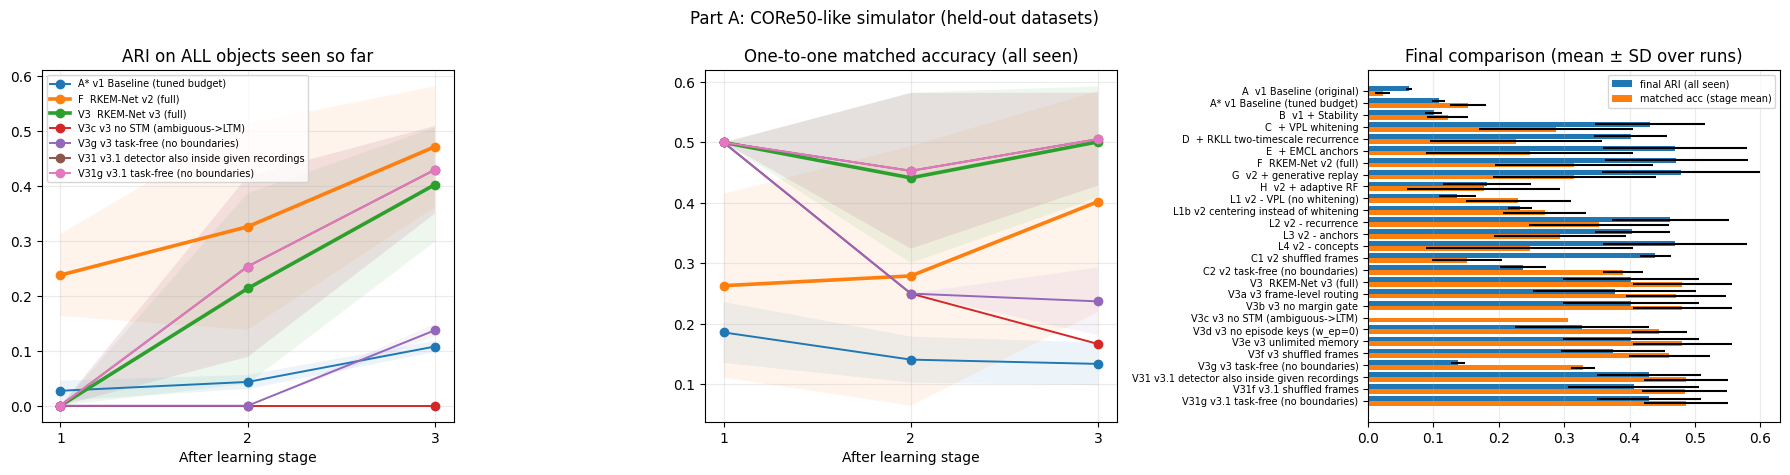

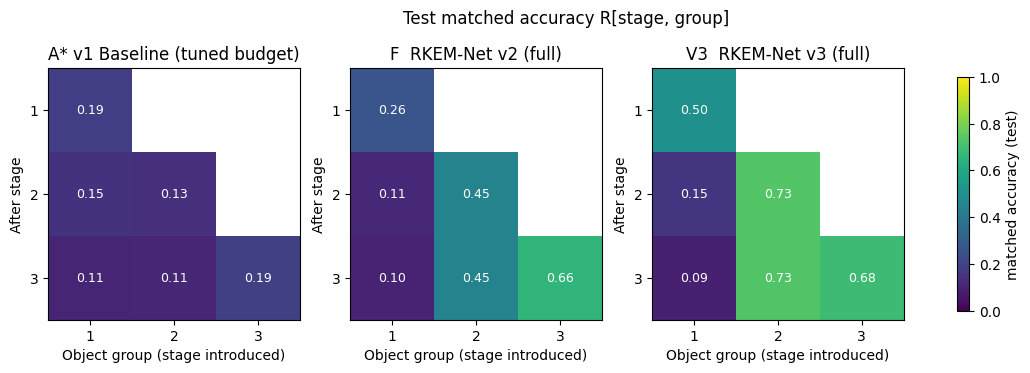

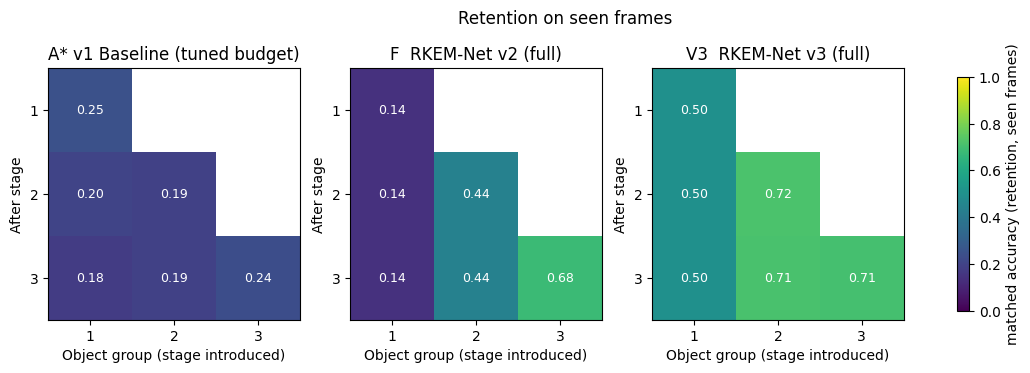

In [8]:
# ============================================================
# RKEM-Net | Section 8: Part A: held-out synthetic evaluation (v1, v2, v3)
# ============================================================

if RUN_SYNTHETIC:
    A_DIR = OUT_ROOT / 'partA_synthetic'; A_DIR.mkdir(exist_ok=True)
    stages_A = ((0, 1), (2, 3), (4, 5))
    datasets = (200, 201, 202, 203, 204) if SYNTHETIC_FULL else (200, 201)
    orders = (11, 22, 33, 44, 55) if SYNTHETIC_FULL else (11, 22, 33)
    t0 = time.perf_counter()
    PS, FI, RS, UB, MC = [], [], {}, [], []
    for ds in datasets:
        SEQ_A = make_core50_like(seed=ds)
        ps, fi, _, rs = run_all(SEQ_A, stages_A, orders, verbose=False)
        ps['dataset'] = fi['dataset'] = ds
        PS.append(ps); FI.append(fi)
        RS.update({(v, ds * 100 + s): R for (v, s), R in rs.items()})
        for m in ('none', 'center', 'whiten'):
            UB.append(dict(dataset=ds, features=m, **offline_upper_bound(SEQ_A, stages_A, m)))
        mc = memory_curve(SEQ_A, stages_A, orders[:3], V3); mc['dataset'] = ds; MC.append(mc)
        print(f'dataset {ds} done ({time.perf_counter() - t0:.0f}s)', flush=True)
    ps_A = pd.concat(PS); fi_A = pd.concat(FI); mc_A = pd.concat(MC)
    fi_A['seed'] = fi_A['dataset'] * 100 + fi_A['seed']          # unique run id for pairing
    summ_A = summarise(fi_A)
    show = ['ACC', 'BWT', 'RET_ACC', 'RET_Forgetting', 'AUC_matched', 'ARI_seen', 'NMI_seen',
            'HungarianAcc', 'prototypes', 'concepts', 'memory_floats']
    print('\nFINAL (after last stage), mean over', fi_A.seed.nunique(), 'runs')
    display(summ_A[show].round(3))
    pb_A = paired_vs(fi_A, V1_REF, 'AUC_matched')
    p32_A = pd.concat({m: paired_vs(fi_A, V2_REF, m).loc[[V3_REF]] for m in
                       ('AUC_matched', 'ARI_seen', 'RET_ACC', 'RET_F', 'BWT')})
    pf_A = paired_vs(fi_A, V2_REF, 'AUC_matched')
    p3_A = paired_vs(fi_A, V3_REF, 'AUC_matched')
    pret_A = paired_vs(fi_A, V1_REF, 'RET_F')
    print('v3 vs v2 on each metric (paired):'); display(p32_A.round(4))
    print('True forgetting (RET_F) vs v1 — negative = less forgetting:'); display(pret_A.round(4))
    print('v3 ablations (vs full v3, matched accuracy; negative = component helps):')
    display(p3_A[p3_A.index.str.startswith('V3')].round(4))
    mc_sum = mc_A.groupby('budget', sort=False)[['AUC_matched', 'ARI_seen', 'ACC', 'BWT', 'RET_ACC', 'RET_F',
                                                  'prototypes', 'memory_floats']].mean()
    print('Memory-budget curve (v3):'); display(mc_sum.round(3))
    print('Offline non-continual reference (k-means, oracle K):')
    display(pd.DataFrame(UB).groupby('features').mean(numeric_only=True).drop(columns='dataset').round(3))
    plot_results(ps_A, fi_A, 'Part A: CORe50-like simulator (held-out datasets)', A_DIR / 'partA_results.png')
    plot_R(RS, [V1_REF, V2_REF, V3_REF], 'Test matched accuracy R[stage, group]', A_DIR / 'partA_R_test.png')
    plot_R(RS, [V1_REF, V2_REF, V3_REF], 'Retention on seen frames', A_DIR / 'partA_R_retention.png',
           which='retention')
    write_evidence(A_DIR, ps_A, fi_A, summ_A, pb_A, pf_A,
                   meta=dict(status='Simulator validation, not CORe50 evidence',
                             protocol=dict(datasets=list(datasets), orders=list(orders), stages=stages_A,
                                           v2_hyperparameters=DEFAULTS | FULL, v3_hyperparameters=DEFAULTS_V3),
                             limitations=['Synthetic data; validates mechanisms only.']),
                   upper=pd.DataFrame(UB), Rs=RS, title='RKEM-Net — Part A (simulator)',
                   extra={'v3_vs_v2_all_metrics': p32_A, 'v3_ablations': p3_A,
                          'retention_forgetting_vs_v1': pret_A, 'memory_curve': mc_sum})

## Part B1: the same features as Experiments 2–6 (legacy cache)

These are the identical frozen ResNet18 vectors: train sessions 1–2, test sessions 9–10, 24/16 frames per
recording. There is no validation session, so **nothing is tuned here**. v2 and v3 use the Part A defaults,
and every model gets a stage-1 budget of 10% of frames (≈10 prototypes, as in Exp 2–6).

In [9]:
# ============================================================
# RKEM-Net | Section 9: CORe50 data pipeline
# ============================================================
# =============================================================================
# RKEM-Net v2 — CORe50 data pipeline (manifest, frame sampling, frozen encoder)
# =============================================================================
import re
import time
import numpy as np
import pandas as pd
from pathlib import Path

# CORe50 categories: o1-5 plug adapters, o6-10 mobile phones, o11-15 scissors,
# o16-20 light bulbs, o21-25 cans, o26-30 glasses, o31-35 balls,
# o36-40 markers, o41-45 cups, o46-50 remote controls.
PROTOCOLS = {
    # Thesis subset (5 plug adapters + 1 phone): fine-grained, hardest case
    'six_objects': ((1, 2), (3, 4), (5, 6)),
    # One instance per category, two categories per stage
    'ten_categories': ((1, 6), (11, 16), (21, 26), (31, 36), (41, 46)),
}

CORE50_CFG = dict(
    protocol='six_objects',
    encoder='resnet18',            # 'resnet18' | 'resnet50' | 'dinov2_vits14' (Internet ON)
    # Official CORe50 test sessions are 3, 7, 10. Session 11 is held out as a
    # VALIDATION session for hyperparameter selection (never used for training).
    train_sessions=[1, 2, 4, 5, 6, 8, 9],
    val_sessions=[11],
    test_sessions=[3, 7, 10],
    frame_stride=5,                # consecutive-ish frames (old protocol: ~12)
    max_frames=60,                 # per recording
    hflip_tta=True,
    batch_size=64,
    num_workers=2,
    seeds=[11, 22, 33, 44, 55],
    tune_seeds=[11, 22, 33],
)


def find_core50_root(search=('/kaggle/input',)):
    for base in search:
        base = Path(base)
        if not base.exists():
            continue
        for p in sorted(base.rglob('core50_128x128')):
            if p.is_dir():
                return p
    return None


def build_core50_manifest(root):
    pat = re.compile(r'^C_(\d+)_(\d+)_(\d+)\.png$', re.IGNORECASE)
    rows = []
    for p in Path(root).glob('s*/o*/*.png'):
        m = pat.fullmatch(p.name)
        if m:
            sid, oid, fr = map(int, m.groups())
            if p.parent.name == f'o{oid}' and p.parent.parent.name == f's{sid}':
                rows.append((sid, oid, fr, str(p)))
    df = pd.DataFrame(rows, columns=['session', 'object', 'frame', 'path'])
    if df.empty:
        raise ValueError('No CORe50 frames matched sN/oM/C_SS_OO_FFF.png')
    df = df.sort_values(['session', 'object', 'frame']).reset_index(drop=True)
    assert not df.duplicated(['session', 'object', 'frame']).any()
    return df


def sample_protocol(manifest, cfg):
    stages = PROTOCOLS[cfg['protocol']]
    objs = [o for s in stages for o in s]
    split_of = {**{s: 'train' for s in cfg['train_sessions']},
                **{s: 'val' for s in cfg['val_sessions']},
                **{s: 'test' for s in cfg['test_sessions']}}
    assert len(split_of) == len(cfg['train_sessions']) + len(cfg['val_sessions']) + len(cfg['test_sessions']), \
        'A session is assigned to more than one split'
    sub = manifest[manifest.object.isin(objs) & manifest.session.isin(split_of)]
    parts = []
    for (sid, oid), g in sub.groupby(['session', 'object'], sort=True):
        g = g.sort_values('frame').iloc[::cfg['frame_stride']].iloc[:cfg['max_frames']].copy()
        g['split'] = split_of[sid]
        parts.append(g)
    out = pd.concat(parts, ignore_index=True)
    for sp in ('train', 'val', 'test'):
        missing = set(objs) - set(out[out.split == sp].object)
        assert not missing, f'objects {missing} missing from {sp} split'
    for a, b in (('train', 'val'), ('train', 'test'), ('val', 'test')):
        assert set(out[out.split == a].session).isdisjoint(out[out.split == b].session)
    return out.sort_values(['split', 'session', 'object', 'frame']).reset_index(drop=True), stages


def build_encoder(name, device):
    import torch
    from torchvision import transforms as T
    if name in ('resnet18', 'resnet50'):
        from torchvision import models
        w = (models.ResNet18_Weights.IMAGENET1K_V1 if name == 'resnet18'
             else models.ResNet50_Weights.IMAGENET1K_V2)
        try:
            net = getattr(models, name)(weights=w)
        except Exception as exc:
            raise RuntimeError('Pretrained weights unavailable: turn Kaggle Internet ON '
                               'or attach cached weights. Never use random weights.') from exc
        net.fc = torch.nn.Identity()
        tf = w.transforms()
    elif name.startswith('dinov2'):
        net = torch.hub.load('facebookresearch/dinov2', name)   # CLS embedding
        tf = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC),
                        T.CenterCrop(224), T.ToTensor(),
                        T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
    else:
        raise ValueError(name)
    net = net.to(device).eval()
    for p in net.parameters():
        p.requires_grad_(False)
    return net, tf


def extract_features(frame, cfg, cache_path):
    """Frozen-encoder embeddings, cached and verified against image paths."""
    cache_path = Path(cache_path)
    paths = frame.path.astype(str).to_numpy()
    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as z:
            X, cached = z['features'], z['paths'].astype(str)
        if np.array_equal(cached, paths):
            print('Loaded cached features:', cache_path.name, X.shape)
            return X.astype(np.float32)
        print('Cache does not match current sample; recomputing.')
    import torch
    from PIL import Image
    from torch.utils.data import Dataset, DataLoader
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    net, tf = build_encoder(cfg['encoder'], device)

    class Frames(Dataset):
        def __len__(self):
            return len(paths)

        def __getitem__(self, i):
            with Image.open(paths[i]) as im:
                return tf(im.convert('RGB')), i

    loader = DataLoader(Frames(), batch_size=cfg['batch_size'], shuffle=False,
                        num_workers=cfg['num_workers'], pin_memory=device == 'cuda')
    out, t0 = None, time.perf_counter()
    with torch.inference_mode():
        for x, idx in loader:
            x = x.to(device)
            f = net(x).float()
            if cfg['hflip_tta']:
                f = (f + net(torch.flip(x, dims=[3])).float()) / 2
            f = torch.nn.functional.normalize(f, dim=1).cpu().numpy()
            if out is None:
                out = np.empty((len(paths), f.shape[1]), np.float32)
            out[idx.numpy()] = f
    assert np.isfinite(out).all()
    np.savez_compressed(cache_path, features=out, paths=paths.astype('U'))
    print(f'Encoded {len(paths)} frames with {cfg["encoder"]} on {device} '
          f'in {time.perf_counter() - t0:.0f}s ->', cache_path.name)
    return out


def to_sequences(frame, X):
    """{(split, session, object): (T, D) features in frame order}."""
    frame = frame.reset_index(drop=True)
    SEQ = {}
    for (sp, sid, oid), g in frame.groupby(['split', 'session', 'object'], sort=True):
        g = g.sort_values('frame')
        SEQ[(str(sp), int(sid), int(oid))] = X[g.index.to_numpy()].astype(np.float32)
    return SEQ


def find_legacy_cache(search=('/kaggle/working/rkem_core50_evidence', '/kaggle/input')):
    """Experiment-1 cache (sampled_manifest.csv + sampled_resnet18_features.npz)."""
    for base in search:
        base = Path(base)
        if not base.exists():
            continue
        hits = [base / 'sampled_resnet18_features.npz'] if (base / 'sampled_resnet18_features.npz').exists() \
            else sorted(base.rglob('sampled_resnet18_features.npz'))
        for npz in hits:
            if (npz.parent / 'sampled_manifest.csv').exists():
                return npz.parent
    return None


def load_legacy_sequences(folder):
    folder = Path(folder)
    man = pd.read_csv(folder / 'sampled_manifest.csv').reset_index(drop=True)
    with np.load(folder / 'sampled_resnet18_features.npz', allow_pickle=True) as z:
        X = np.asarray(z['features'], np.float32); P = np.asarray(z['paths']).astype(str)
    assert len(X) == len(man) and np.array_equal(P, man.path.astype(str).to_numpy())
    assert set(man[man.split == 'train'].session).isdisjoint(man[man.split == 'test'].session)
    return to_sequences(man, X)

In [10]:
# ============================================================
# RKEM-Net | Section 10: Part B1: legacy cache — v1, v2, v3 on identical features
# ============================================================

def report_block(SEQ, stages, variants, hp, seeds, out, title, eval_split='test', tuned_meta=None,
                 limitations=()):
    ps, fi, summ, RS = run_all(SEQ, stages, seeds, variants, hp, eval_split=eval_split)
    pb = paired_vs(fi, V1_REF, 'AUC_matched'); pf = paired_vs(fi, V2_REF, 'AUC_matched')
    p3 = paired_vs(fi, V3_REF, 'AUC_matched')
    p32 = pd.concat({m: paired_vs(fi, V2_REF, m).loc[[V3_REF]] for m in
                     ('AUC_matched', 'ARI_seen', 'RET_ACC', 'RET_F', 'BWT')})
    pret = paired_vs(fi, V1_REF, 'RET_F')
    ub = [dict(features=m, **offline_upper_bound(SEQ, stages, m, eval_split)) for m in ('none', 'center', 'whiten')]
    show = ['ACC', 'BWT', 'RET_ACC', 'RET_Forgetting', 'AUC_matched', 'ARI_seen', 'NMI_seen',
            'HungarianAcc', 'prototypes', 'concepts', 'memory_floats']
    display(summ[show].round(3))
    print('v3 vs v2 (paired):'); display(p32.round(4))
    print('True forgetting vs v1:'); display(pret.round(4))
    print('v3 ablations:'); display(p3[p3.index.str.startswith('V3')].round(4))
    display(pd.DataFrame(ub).round(3))
    plot_results(ps, fi, title, out / 'results.png')
    plot_R(RS, [V1_REF, V2_REF, V3_REF], f'{title}: test R', out / 'R_test.png')
    plot_R(RS, [V1_REF, V2_REF, V3_REF], f'{title}: retention', out / 'R_retention.png', which='retention')
    write_evidence(out, ps, fi, summ, pb, pf,
                   meta=dict(status=tuned_meta.pop('status') if tuned_meta else 'measured',
                             protocol=tuned_meta or {}, limitations=list(limitations)),
                   upper=ub, Rs=RS, title=title,
                   extra={'v3_vs_v2_all_metrics': p32, 'v3_ablations': p3, 'retention_forgetting_vs_v1': pret})
    return summ


LEGACY = find_legacy_cache(LEGACY_SEARCH) if RUN_LEGACY_CACHE else None
if LEGACY is None:
    print('Legacy Experiment-1 cache not found -> Part B1 skipped. '
          '(Attach the old notebook via Add Input -> Notebook Output Files.)')
else:
    B1_DIR = OUT_ROOT / 'partB1_legacy_cache'; B1_DIR.mkdir(exist_ok=True)
    SEQ_L = load_legacy_sequences(LEGACY)
    stages_L = PROTOCOLS['six_objects']
    print('Legacy cache:', LEGACY, '| recordings:', len(SEQ_L))
    legacy_tuned = dict(v2=dict(vpl=FULL['vpl'], sigma_scale=DEFAULTS['sigma_scale'],
                                target_node_fraction=0.10, rk=(FULL['af'], FULL['as_'], FULL['rho']),
                                merge_thr=DEFAULTS['merge_thr'], join_thr=DEFAULTS['join_thr'],
                                anchor=FULL['anchor']), v1_node_fraction=0.10)
    var_L, hp_L = tuned_variant_table(legacy_tuned)
    report_block(SEQ_L, stages_L, var_L, hp_L, (11, 22, 33, 44, 55), B1_DIR,
                 'Part B1: CORe50 legacy features (sessions 1-2 -> 9-10)',
                 tuned_meta=dict(status='Measured on CORe50 legacy cache; hyperparameters NOT tuned on this data',
                                 source=str(LEGACY), stages=stages_L, train_sessions=[1, 2],
                                 test_sessions=[9, 10], hyperparameters=hp_L),
                 limitations=['Custom 6-object subset (5 plug adapters + 1 phone), not the official benchmark.',
                              'Sessions 9/10 were inspected in Exp 1-6; this is not an untouched test set.',
                              'Five orders reorder the same 24 recordings; not independent datasets.',
                              'Sparse frames (~12 apart) and short recordings limit episode-level mechanisms.'])

Legacy Experiment-1 cache not found -> Part B1 skipped. (Attach the old notebook via Add Input -> Notebook Output Files.)


## Part B2: new CORe50 protocol (recommended for the thesis)

* **Sessions:** train 1, 2, 4, 5, 6, 8, 9; **validation 11** (all tuning, for v1, v2 and v3); **test 3, 7, 10** (official CORe50 test sessions, used once).
* **Frames:** every 5th frame, 60 per recording.
* **Protocols:** `six_objects` (fine-grained thesis subset) and `ten_categories` (one instance per category, 5 stages).
* **Encoder:** `resnet18` for continuity; `dinov2_vits14` is an optional VPL ablation (needs Internet ON).
* Use a GPU for feature extraction. Everything else runs on CPU, roughly 10–20 min per protocol.

CORe50 root: /kaggle/input/datasets/sana15/core50-rgb-dataset-rkem-research/core50_128x128
Indexed 164866 frames; 11 sessions, 50 objects

=== six_objects_resnet18_stride5:  {'test': 1080, 'train': 2520, 'val': 360}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


Encoded 3960 frames with resnet18 on cuda in 126s -> features_six_objects_resnet18_stride5.npz
  val improve: sigma_scale=0.9 -> 0.3758
v2 selected on val (151s): {'vpl': 'whiten', 'sigma_scale': 0.9, 'target_node_fraction': 0.02, 'rk': (0.5, 0.9, 0.5), 'merge_thr': 0.2, 'join_thr': 0.5, 'anchor': 0.2} | v1 budget: 0.05
  v3 val start: 0.4655
  v3 val improve: w_ep=0.75 -> 0.4803
v3 selected on val (108s): {'tau_stm': 0.2, 'merge_ep': 0.45, 'w_ep': 0.75, 'ep_sigma_scale': 0.5, 'tau_match': 0.6, 'margin': 0.1, 'join_ep': 0.7}
seed 11 done
seed 22 done
seed 33 done
seed 44 done
seed 55 done


,ACC,BWT,RET_ACC,RET_Forgetting,AUC_matched,ARI_seen,NMI_seen,HungarianAcc,prototypes,concepts,memory_floats
variant,,,,,,,,,,,
A v1 Baseline (original),0.257,-0.046,0.182,0.025,0.262,0.182,0.403,0.319,200.0,200.0,102800.0
A* v1 Baseline (tuned budget),0.304,-0.034,0.210,0.040,0.307,0.208,0.392,0.355,97.4,97.4,50063.6
B v1 + Stability,0.414,-0.115,0.278,0.059,0.418,0.278,0.441,0.445,62.6,62.6,32176.4
C + VPL,0.243,-0.210,0.264,0.185,0.251,0.095,0.233,0.316,9.2,9.2,1196.0
D + RKLL two-timescale recurrence,0.399,-0.083,0.368,0.058,0.308,0.343,0.510,0.518,16.6,16.6,4282.8
E + EMCL anchors,0.410,0.014,0.395,0.007,0.307,0.347,0.534,0.499,17.4,17.4,4489.2
F RKEM-Net v2 (full),0.446,0.014,0.396,0.007,0.372,0.347,0.534,0.499,17.4,17.0,4489.2
G v2 + generative replay,0.440,-0.003,0.393,0.009,0.373,0.341,0.523,0.497,17.6,17.2,4540.8
L1 v2 - VPL,0.520,-0.114,0.322,0.073,0.547,0.402,0.574,0.543,28.4,20.8,29138.4


v3 vs v2 (paired):


,,mean_gain,sd_gain,wins,n,wilcoxon_p
,variant,,,,,
AUC_matched,V3 RKEM-Net v3 (full),0.1177,0.0234,5,5,0.0625
ARI_seen,V3 RKEM-Net v3 (full),-0.0426,0.0273,0,5,0.0625
RET_ACC,V3 RKEM-Net v3 (full),0.1091,0.0180,5,5,0.0625
RET_F,V3 RKEM-Net v3 (full),0.0425,0.1059,1,5,0.8750
BWT,V3 RKEM-Net v3 (full),-0.0933,0.1103,1,5,0.1250


True forgetting vs v1:


,mean_gain,sd_gain,wins,n,wilcoxon_p
variant,,,,,
A v1 Baseline (original),-0.0148,0.0431,2,5,0.6250
B v1 + Stability,0.0185,0.0420,3,5,0.4375
C + VPL,0.1443,0.0435,5,5,0.0625
C1 v2 shuffled frames,-0.0294,0.0338,1,5,0.1875
C2 v2 task-free (no boundaries),0.1512,0.1005,4,5,0.1250
D + RKLL two-timescale recurrence,0.0173,0.0526,3,5,0.6250
E + EMCL anchors,-0.0331,0.0461,1,5,0.3125
F RKEM-Net v2 (full),-0.0331,0.0461,1,5,0.3125
G v2 + generative replay,-0.0313,0.0472,1,5,0.3125


v3 ablations:


,mean_gain,sd_gain,wins,n,wilcoxon_p
variant,,,,,
V31 v3.1 detector also inside given recordings,-0.0727,0.0516,1,5,0.1250
V31f v3.1 shuffled frames,-0.0915,0.0375,0,5,0.0625
V31g v3.1 task-free (no boundaries),-0.0534,0.0430,1,5,0.1250
V3a v3 frame-level routing,-0.0306,0.0059,0,5,0.0625
V3b v3 no margin gate,0.0000,0.0000,0,5,1.0000
V3c v3 no STM (ambiguous->LTM),-0.1846,0.0036,0,5,0.0625
V3d v3 no episode keys (w_ep=0),-0.1846,0.0036,0,5,0.0625
V3e v3 unlimited memory,0.0000,0.0000,0,5,1.0000
V3f v3 shuffled frames,-0.0170,0.0040,0,5,0.0625


,features,ARI_seen,NMI_seen,HungarianAcc_seen,MatchedAcc_seen,ProbeAcc_seen,supervised_1NN_acc
0,none,0.219,0.309,0.437,0.421,0.425,0.694
1,center,0.217,0.303,0.435,0.429,0.438,0.689
2,whiten,0.277,0.421,0.506,0.506,0.506,0.630


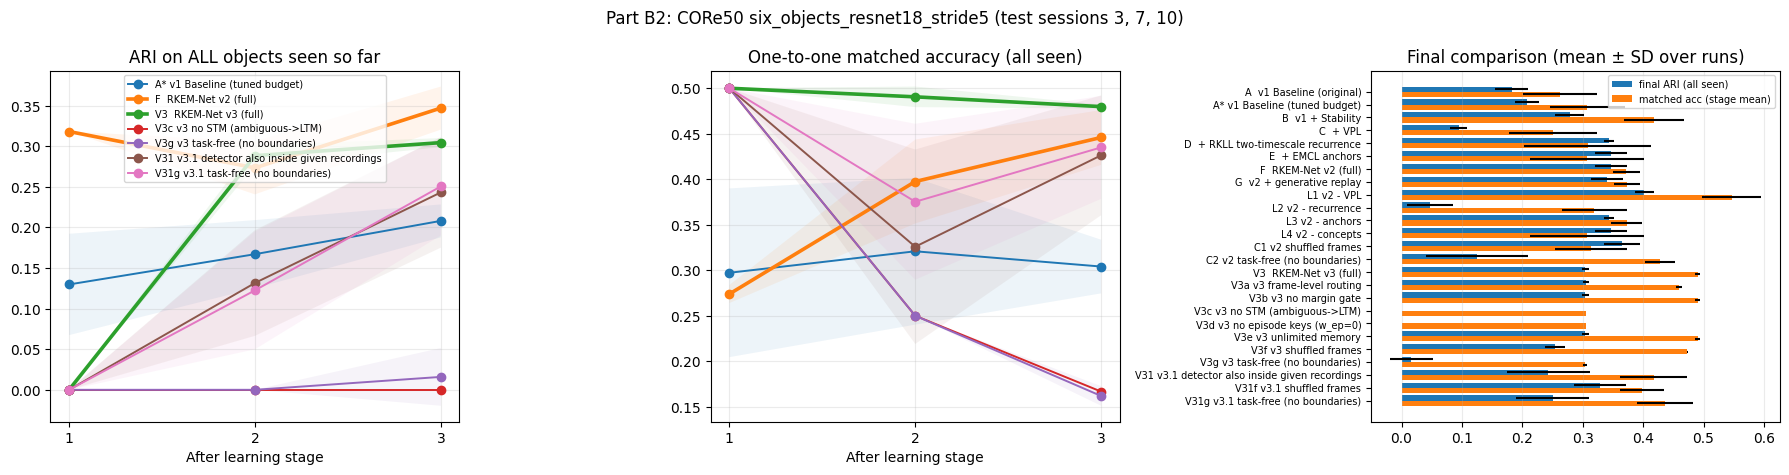

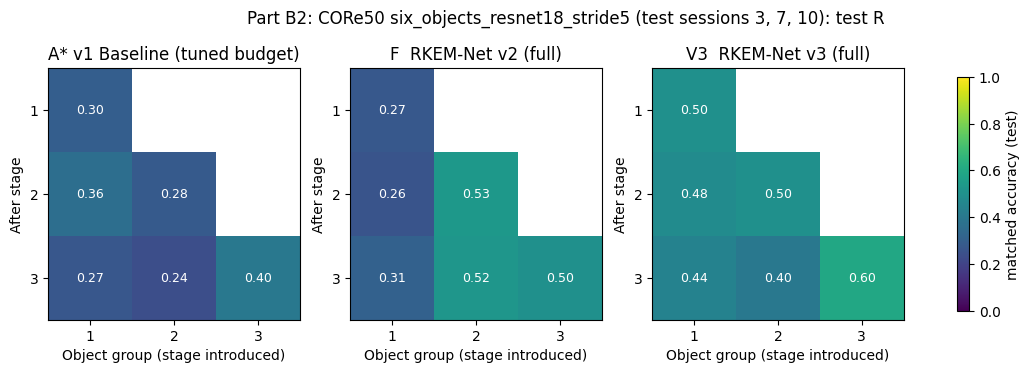

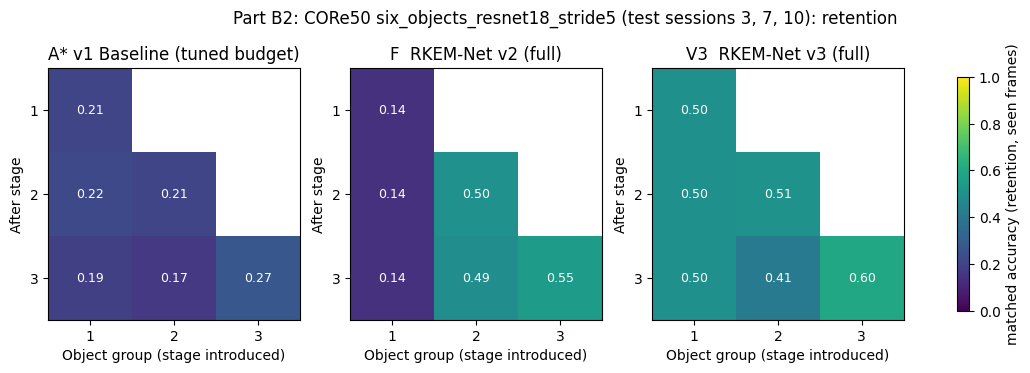

Memory-budget curve (v3):


,ACC,BWT,RET_ACC,RET_F,AUC_matched,ARI_seen,prototypes,memory_floats
budget,,,,,,,,
8,0.469,-0.134,0.508,0.083,0.490,0.296,8.0,11650.667
16,0.483,-0.112,0.508,0.082,0.494,0.313,16.0,13706.667
24,0.480,-0.118,0.508,0.083,0.492,0.304,21.0,14991.667
32,0.480,-0.118,0.508,0.083,0.492,0.304,21.0,14991.667
48,0.480,-0.118,0.508,0.083,0.492,0.304,21.0,14991.667
64,0.480,-0.118,0.508,0.083,0.492,0.304,21.0,14991.667
unlimited,0.480,-0.118,0.508,0.083,0.492,0.304,21.0,14991.667



=== ten_categories_resnet18_stride5:  {'test': 1800, 'train': 4199, 'val': 600}
Encoded 6599 frames with resnet18 on cuda in 178s -> features_ten_categories_resnet18_stride5.npz
  val improve: rk=(0.5, 0.95, 0.5) -> 0.6813
  val improve: sigma_scale=0.9 -> 0.6991
v2 selected on val (178s): {'vpl': 'whiten', 'sigma_scale': 0.9, 'target_node_fraction': 0.02, 'rk': (0.5, 0.95, 0.5), 'merge_thr': 0.2, 'join_thr': 0.5, 'anchor': 0.2} | v1 budget: 0.01
  v3 val start: 0.5659
  v3 val improve: w_ep=0.75 -> 0.6400
  v3 val improve: tau_match=0.7 -> 0.6923
  v3 val improve: tau_stm=0.5 -> 0.7642
v3 selected on val (153s): {'tau_stm': 0.5, 'merge_ep': 0.45, 'w_ep': 0.75, 'ep_sigma_scale': 0.5, 'tau_match': 0.7, 'margin': 0.1, 'join_ep': 0.7}
seed 11 done
seed 22 done
seed 33 done
seed 44 done
seed 55 done


,ACC,BWT,RET_ACC,RET_Forgetting,AUC_matched,ARI_seen,NMI_seen,HungarianAcc,prototypes,concepts,memory_floats
variant,,,,,,,,,,,
A v1 Baseline (original),0.274,-0.003,0.174,0.000,0.259,0.283,0.643,0.334,585.8,585.8,301101.2
A* v1 Baseline (tuned budget),0.479,-0.141,0.351,0.149,0.527,0.350,0.550,0.503,27.2,27.2,13980.8
B v1 + Stability,0.558,-0.196,0.418,0.122,0.634,0.486,0.652,0.578,16.6,16.6,8532.4
C + VPL,0.425,-0.210,0.394,0.194,0.443,0.366,0.531,0.444,10.2,10.2,1326.0
D + RKLL two-timescale recurrence,0.711,-0.023,0.661,0.007,0.540,0.793,0.903,0.764,26.0,26.0,6708.0
E + EMCL anchors,0.752,-0.020,0.702,0.011,0.572,0.837,0.913,0.817,27.2,27.2,7017.6
F RKEM-Net v2 (full),0.733,-0.019,0.706,0.011,0.527,0.836,0.912,0.817,27.2,25.6,7017.6
G v2 + generative replay,0.733,-0.019,0.708,0.011,0.527,0.836,0.912,0.817,27.2,25.6,7017.6
L1 v2 - VPL,0.424,-0.001,0.269,0.000,0.431,0.599,0.805,0.585,88.8,61.2,91108.8


v3 vs v2 (paired):


,,mean_gain,sd_gain,wins,n,wilcoxon_p
,variant,,,,,
AUC_matched,V3 RKEM-Net v3 (full),0.1148,0.0742,5,5,0.0625
ARI_seen,V3 RKEM-Net v3 (full),0.0554,0.0877,4,5,0.3125
RET_ACC,V3 RKEM-Net v3 (full),0.0652,0.0945,4,5,0.3125
RET_F,V3 RKEM-Net v3 (full),-0.0107,0.0159,1,5,0.2500
BWT,V3 RKEM-Net v3 (full),0.0349,0.0385,3,5,0.3125


True forgetting vs v1:


,mean_gain,sd_gain,wins,n,wilcoxon_p
variant,,,,,
A v1 Baseline (original),-0.1493,0.0792,0,5,0.0625
B v1 + Stability,-0.0273,0.0986,2,5,0.4375
C + VPL,0.0442,0.0608,3,5,0.3125
C1 v2 shuffled frames,-0.1347,0.0699,0,5,0.0625
C2 v2 task-free (no boundaries),-0.1494,0.0794,0,5,0.0625
D + RKLL two-timescale recurrence,-0.1419,0.0662,0,5,0.0625
E + EMCL anchors,-0.1387,0.0727,0,5,0.0625
F RKEM-Net v2 (full),-0.1387,0.0727,0,5,0.0625
G v2 + generative replay,-0.1387,0.0729,0,5,0.0625


v3 ablations:


,mean_gain,sd_gain,wins,n,wilcoxon_p
variant,,,,,
V31 v3.1 detector also inside given recordings,-0.0832,0.0709,1,5,0.1250
V31f v3.1 shuffled frames,-0.1846,0.0491,0,5,0.0625
V31g v3.1 task-free (no boundaries),-0.0840,0.0731,1,5,0.1250
V3a v3 frame-level routing,0.0093,0.0205,2,5,0.5000
V3b v3 no margin gate,0.0000,0.0000,0,5,1.0000
V3c v3 no STM (ambiguous->LTM),-0.2679,0.0246,0,5,0.0625
V3d v3 no episode keys (w_ep=0),-0.1446,0.0633,0,5,0.0625
V3e v3 unlimited memory,0.0000,0.0000,0,5,1.0000
V3f v3 shuffled frames,-0.0163,0.0324,2,5,0.4375


,features,ARI_seen,NMI_seen,HungarianAcc_seen,MatchedAcc_seen,ProbeAcc_seen,supervised_1NN_acc
0,none,0.572,0.688,0.620,0.615,0.615,0.933
1,center,0.543,0.678,0.627,0.619,0.608,0.933
2,whiten,0.557,0.764,0.759,0.756,0.759,0.911


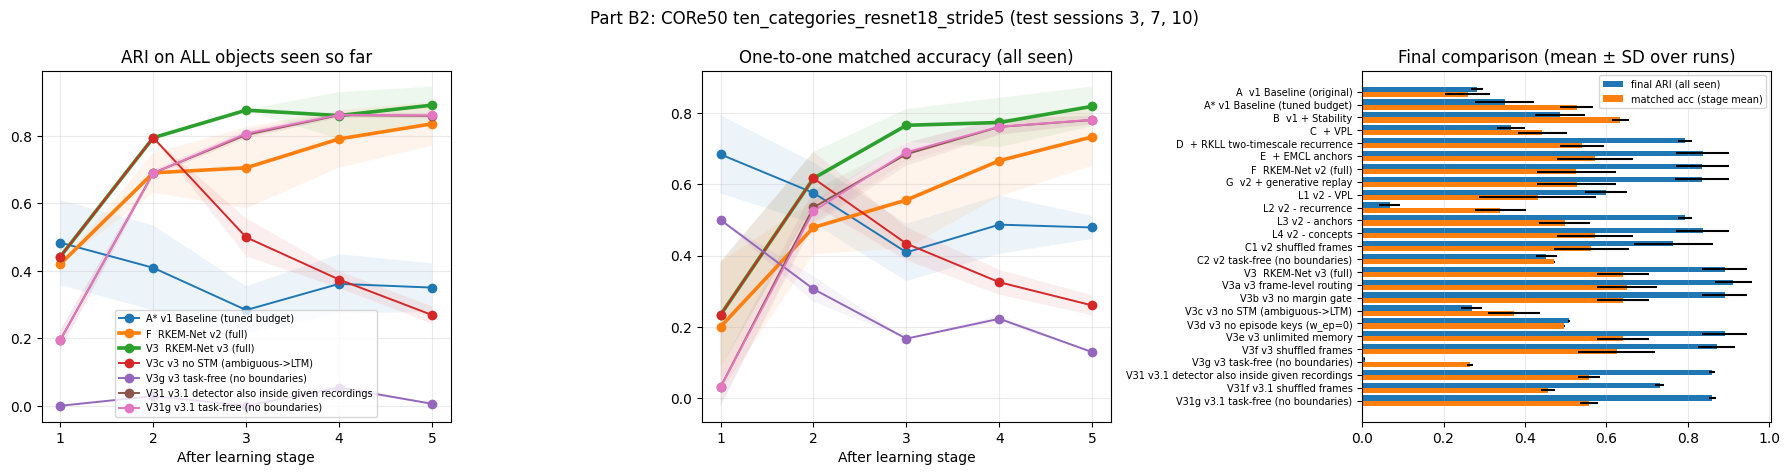

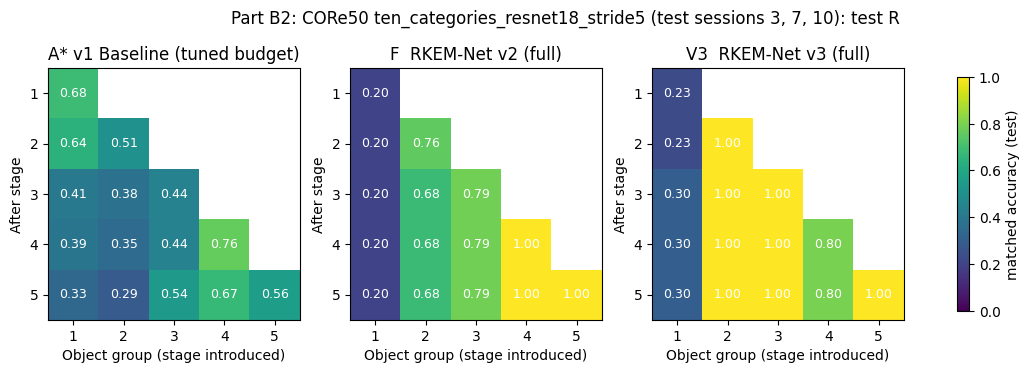

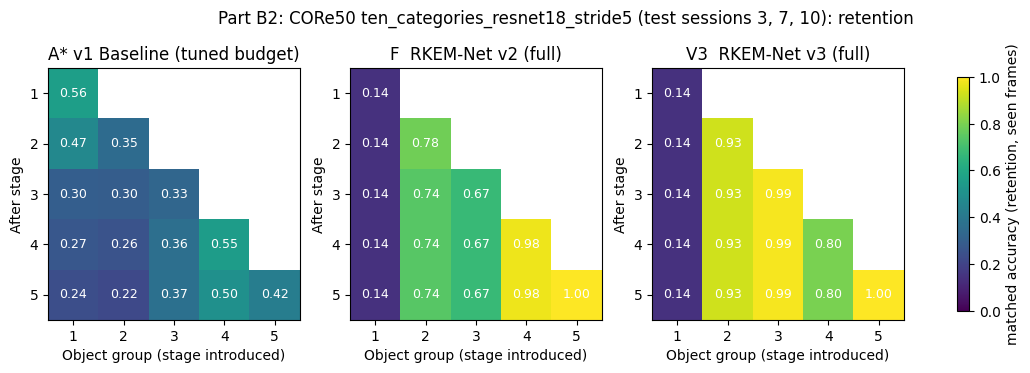

Memory-budget curve (v3):


,ACC,BWT,RET_ACC,RET_F,AUC_matched,ARI_seen,prototypes,memory_floats
budget,,,,,,,,
8,0.766,-0.116,0.757,0.082,0.675,0.695,8.0,16533.667
16,0.823,-0.012,0.802,-0.008,0.685,0.835,16.0,20645.667
24,0.843,0.013,0.781,0.000,0.688,0.898,24.0,24158.000
32,0.843,0.013,0.781,0.000,0.688,0.898,29.0,25443.000
48,0.843,0.013,0.781,0.000,0.688,0.898,29.0,25443.000
64,0.843,0.013,0.781,0.000,0.688,0.898,29.0,25443.000
unlimited,0.843,0.013,0.781,0.000,0.688,0.898,29.0,25443.000


In [11]:
# ============================================================
# RKEM-Net | Section 11: Part B2: new CORe50 protocol
# ============================================================

B2_RUNS = [dict(protocol='six_objects', encoder='resnet18'),
           dict(protocol='ten_categories', encoder='resnet18'),
           # dict(protocol='six_objects', encoder='dinov2_vits14'),   # VPL encoder ablation
           ]
CORE50_ROOT = find_core50_root(CORE50_SEARCH) if RUN_CORE50 else None
B2_RESULTS = {}
if CORE50_ROOT is None:
    print('CORe50 image folder not found -> Part B2 skipped. Attach core50_128x128 on Kaggle.')
else:
    print('CORe50 root:', CORE50_ROOT)
    MANIFEST = build_core50_manifest(CORE50_ROOT)
    print('Indexed', len(MANIFEST), 'frames;', MANIFEST.session.nunique(), 'sessions,',
          MANIFEST.object.nunique(), 'objects')
    for run in B2_RUNS:
        cfg = dict(CORE50_CFG, **run)
        tag = f"{cfg['protocol']}_{cfg['encoder']}_stride{cfg['frame_stride']}"
        out = OUT_ROOT / f'partB2_{tag}'; out.mkdir(exist_ok=True)
        frame, stages = sample_protocol(MANIFEST, cfg)
        frame.to_csv(out / 'sampled_manifest.csv', index=False)
        print(f'\n=== {tag}: ', frame.groupby('split').size().to_dict(), flush=True)
        X = extract_features(frame, cfg, OUT_ROOT / f'features_{tag}.npz')
        SEQ = to_sequences(frame, X)
        # ---- 1) v1/v2 hyperparameters: VALIDATION session only ----
        t0 = time.perf_counter()
        tuned = tune_on_validation(SEQ, stages, seeds=cfg['tune_seeds'])
        tuned['log'].to_csv(out / 'validation_tuning_log_v2.csv', index=False)
        print(f"v2 selected on val ({time.perf_counter() - t0:.0f}s):", tuned['v2'],
              '| v1 budget:', tuned['v1_node_fraction'])
        # ---- 2) v3 knobs: VALIDATION session only, on top of the tuned v2 front-end ----
        variants, hp = tuned_variant_table(tuned)
        t0 = time.perf_counter()
        t3 = tune_v3_on_validation([SEQ], stages, seeds=cfg['tune_seeds'][:2],
                                   base_cfg=variants[V3_REF], base_hp=hp)
        tuned['v3'] = t3['v3']
        print(f"v3 selected on val ({time.perf_counter() - t0:.0f}s):", t3['v3'])
        variants, hp = tuned_variant_table(tuned)
        # ---- 3) single evaluation on the official test sessions ----
        summ = report_block(SEQ, stages, variants, hp, cfg['seeds'], out,
                            f'Part B2: CORe50 {tag} (test sessions 3, 7, 10)',
                            tuned_meta=dict(status='Measured on CORe50; hyperparameters selected on validation session only',
                                            **cfg, stages=stages, tuned_v2=tuned['v2'], tuned_v3=tuned['v3'],
                                            v1_node_fraction=tuned['v1_node_fraction'], hyperparameters=hp),
                            limitations=['Frozen encoder: forgetting is measured in the prototype/concept layer.',
                                         'The five orders share the same images (recording order randomised).',
                                         'Task-free controls concatenate recordings; real streams may have softer boundaries.',
                                         'Matched/probe maps use training labels after learning, for evaluation only.'])
        mc = memory_curve(SEQ, stages, cfg['seeds'][:3], variants[V3_REF], hp)
        mcs = mc.groupby('budget', sort=False).mean(numeric_only=True).drop(columns='seed')
        mcs.to_csv(out / 'memory_curve.csv'); print('Memory-budget curve (v3):'); display(mcs.round(3))
        B2_RESULTS[tag] = summ

## Section 13: Published baselines under the same protocol

RKEM-Net is compared with two earlier unsupervised continual learners that keep **short- and long-term memories**,
using the **authors' official code**, unmodified:

| Method | Official code | What is used | Input |
|---|---|---|---|
| GDM episodic memory, Parisi et al. (2018), *Frontiers in Neurorobotics* | github.com/giparisi/GDM | `EpisodicGWR` (Gamma-GWR with temporal context), labels set to −1, `regulated=0` | the same frozen ResNet18 features + the same label-free VPL whitening |
| STAM, Smith et al. (2021), *IJCAI* | github.com/CameronTaylorFL/stam | `StamWrapper` with the repository's CORe50 layer architecture | the same sampled CORe50 frames as 64×64 RGB images (the repository's own CORe50 resizing) |

**Same protocol as RKEM-Net:** same objects and stages, same recording order per seed, train sessions for learning,
validation session 11 for any tuning, test sessions 3/7/10 once, the same metrics (one-to-one matched map fitted on
training frames, ARI on all seen objects, retention on seen training frames).

**Settings.** GDM: activation threshold chosen on validation session 11 from 0.42–0.55 (seeds 11/22/33), other values
from the authors' demo (β = 0.5, learning rates 0.2 / 0.001, one context step); each neuron is one cluster.
GDM's semantic memory is driven by label signals, so only its unsupervised episodic memory is used.
STAM: the authors' natural-image setting (δ = 2500, α = 0.1, β = 0.95, θ = 30, ρ = 0.15), no tuning; clustering as in
the STAM paper, by k-means on the long-term-centroid embedding, with K = number of objects seen (which gives STAM
the true number of objects, an advantage RKEM-Net does not get).

**Boundaries.** Neither GDM nor STAM uses recording boundaries, so the fairest RKEM-Net comparison for them is
v3.1 (no boundaries); v3 (boundaries given) is shown as the full model.

**Runtime.** GDM: about 2 minutes. STAM learns from raw pixel patches and is very slow: in a full attempt, not one
of 10 runs finished within Kaggle's 12-hour limit. The full STAM run is therefore off (`RUN_STAM = False`), and
**Section 13e measures its cost instead**: official STAM learns the real CORe50 frames of the first six-objects stage (time budget 30 minutes), the seconds per
image are saved to `published_baselines/stam_timing.csv`, and the time for one full run is estimated from the latest
(slowest) rate. This estimate is a lower bound, because STAM keeps slowing as its memory grows.


In [12]:
# ===================== RKEM-Net | Section 13a: protocol runner for external baselines =====================
# Scores any external method with EXACTLY the RKEM protocol: same stages, same recording order per seed,
# same evaluation order, one-to-one matched map fitted on TRAINING frames, ARI, R / retention matrices.
import sys, os, json, subprocess, importlib
from pathlib import Path
EXT_ROOT = OUT_ROOT.parent / 'rkem_external'      # third-party code lives outside the evidence folder
EXT_ROOT.mkdir(parents=True, exist_ok=True)

def run_external(SEQ, stages, seed, make_adapter, eval_split='test'):
    t0 = time.perf_counter()
    adapter = make_adapter(SEQ, stages, seed)
    train = {}
    for si, objs in enumerate(stages):
        orng = np.random.default_rng(seed + 101 * (si + 1))          # same order as run_variant
        keys = _keys(SEQ, 'train', objs)
        train[si] = [keys[i] for i in orng.permutation(len(keys))]
    order = np.random.default_rng(12345)                             # same eval order as run_variant
    T = len(stages)
    R = np.full((T, T), np.nan); Rp = np.full((T, T), np.nan); Rr = np.full((T, T), np.nan)
    rows = []
    for si, objs in enumerate(stages):
        adapter.learn(train[si], si)
        seen = [o for s in stages[:si + 1] for o in s]
        ek = _keys(SEQ, eval_split, seen); ek = [ek[i] for i in order.permutation(len(ek))]
        tr = [k for s in range(si + 1) for k in train[s]]
        p, ptr = adapter.predict(ek, tr, len(seen))
        y = np.concatenate([[k[2]] * len(SEQ[k]) for k in ek])
        ytr = np.concatenate([[k[2]] * len(SEQ[k]) for k in tr])
        mp = probe_map(ptr, ytr); mm = matched_map(ptr, ytr)
        yhat = np.array([mp.get(int(c), -1) for c in p]); ymat = np.array([mm.get(int(c), -1) for c in p])
        ari, nmi = ari_nmi(y, p)
        for g in range(si + 1):
            msk = np.isin(y, stages[g]); mtr = np.isin(ytr, stages[g])
            R[si, g] = float(np.mean(ymat[msk] == y[msk])); Rp[si, g] = float(np.mean(yhat[msk] == y[msk]))
            Rr[si, g] = float(np.mean(np.array([mm.get(int(c), -1) for c in ptr[mtr]]) == ytr[mtr]))
        rows.append(dict(seed=seed, after_stage=si + 1, ARI_seen=ari, NMI_seen=nmi,
                         MatchedAcc_seen=float(np.mean(ymat == y)), ProbeAcc_seen=float(np.mean(yhat == y)),
                         clusters_used=int(len(np.unique(p))), units=adapter.size()))
    acc, bwt, fgt = continual_summary(R); ret_acc, _, ret_f = continual_summary(Rr)
    return dict(rows=rows, R=R, ACC=acc, BWT=bwt, RET_ACC=ret_acc, RET_F=ret_f,
                ACC_probe=continual_summary(Rp)[0],
                AUC_matched=float(np.mean([r['MatchedAcc_seen'] for r in rows])),
                seconds=time.perf_counter() - t0)

def summarise_external(res, name):
    last = res['rows'][-1]
    return dict(method=name, seed=last['seed'], ACC=res['ACC'], ACC_probe=res['ACC_probe'],
                AUC_matched=res['AUC_matched'], ARI_seen=last['ARI_seen'], RET_ACC=res['RET_ACC'],
                RET_F=res['RET_F'], units=last['units'], seconds=res['seconds'])

def clone(url, folder):
    folder = Path(folder)
    if not folder.exists():
        subprocess.run(['git', 'clone', '-q', url, str(folder)], check=True)
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
    return folder


In [13]:
# ===================== RKEM-Net | Section 13b: official GDM / Episodic Gamma-GWR (Parisi et al., 2018) =====================
# Official code: https://github.com/giparisi/GDM (episodic_gwr.py, gammagwr.py), used unmodified.
# Label-free use: every label is -1 and regulated=0, so labels never affect growth or updates.
# The semantic memory of GDM is driven by label signals, so only the (unsupervised) episodic memory is used.
# Input: the same frozen ResNet18 features with the same label-free VPL whitening as RKEM-Net.
import contextlib, io
GDM_DIR = clone('https://github.com/giparisi/GDM', EXT_ROOT / 'GDM')
EpisodicGWR = importlib.import_module('episodic_gwr').EpisodicGWR

class _DS:                       # minimal dataset object expected by init_network
    def __init__(self, X): self.vectors = X

class GDMAdapter:
    def __init__(self, SEQ, stages, seed, a_threshold=0.5, beta=0.7, lr=(0.2, 0.001), num_context=1):
        s1 = _keys(SEQ, 'train', stages[0])
        self.vpl = LabelFreeVPL('whiten').fit(np.concatenate([SEQ[k] for k in s1]))   # same front end
        self.Z = {k: self.vpl.transform(v) for k, v in SEQ.items()}
        np.random.seed(seed)
        self.net = EpisodicGWR()
        first = self.Z[s1[0]]
        self.net.init_network(_DS(first), [1], num_context)
        self.p = dict(a_threshold=a_threshold, beta=beta, l_rates=list(lr))
    def learn(self, keys, si):   # one online pass over the stage stream, recordings in order
        X = np.concatenate([self.Z[k] for k in keys])
        with contextlib.redirect_stdout(io.StringIO()):
            self.net.train_egwr(X, -np.ones((1, len(X))), 1, self.p['a_threshold'], self.p['beta'],
                                self.p['l_rates'], True, regulated=0)
    def _bmu(self, keys):
        X = np.concatenate([self.Z[k] for k in keys])
        with contextlib.redirect_stdout(io.StringIO()):
            self.net.test(X, -np.ones((1, len(X))))
        return self.net.bmus_index.astype(int)
    def predict(self, eval_keys, train_keys, n_seen):
        return self._bmu(eval_keys), self._bmu(train_keys)   # each neuron = one cluster
    def size(self):
        return int(self.net.num_nodes)


In [14]:
# ===================== RKEM-Net | Section 13c: official STAM (Smith et al., IJCAI 2021) =====================
# Official code: https://github.com/CameronTaylorFL/stam (StamWrapper + Layer), used unmodified.
# STAM learns from raw pixels, so it reads the SAME sampled CORe50 frames as images, resized to 64x64 RGB
# exactly as the repository's own CORe50 loader does (cv2.resize to 64, values 0-255).
# Layers = the repository's CORe50 architecture (model_flag 1). Training is label-free (labels never used).
# Clustering follows the STAM paper: centroid embedding of all layers' LTM centroids, then k-means with
# K = number of objects seen so far, fitted on training frames only; predictions on evaluation frames.
import cv2, contextlib, io, os
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'progressbar33', 'kmodes'], check=False)  # STAM's extra deps
STAM_DIR = clone('https://github.com/CameronTaylorFL/stam', EXT_ROOT / 'stam')
_cwd = os.getcwd(); os.chdir(STAM_DIR)
StamWrapper = importlib.import_module('core.models.stam_wrapper').StamWrapper
os.chdir(_cwd)
from sklearn.cluster import KMeans

STAM_LAYERS_CORE50 = lambda delta, alpha, beta, theta: [
    ['L1', 10, 2, 1, delta, alpha, 0.0, beta, theta],
    ['L2', 18, 2, 2, delta, alpha, 0.0, beta, theta],
    ['L3', 26, 2, 2, delta, alpha, 0.0, beta, theta]]      # from core/config.py, dataset == 'core50'

def load_images(frame, size=64):
    """{(split, session, object): (T, 64, 64, 3) uint8} in the same frame order as to_sequences."""
    frame = frame.reset_index(drop=True); IMG = {}
    for (sp, sid, oid), g in frame.groupby(['split', 'session', 'object'], sort=True):
        g = g.sort_values('frame')
        ims = [cv2.resize(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB), (size, size)) for p in g.path]
        IMG[(str(sp), int(sid), int(oid))] = np.asarray(ims, np.float32)
    return IMG

class STAMAdapter:
    def __init__(self, IMG, stages, seed, delta=2500, alpha=0.1, beta=0.95, theta=30, rho=0.15, workdir=None):
        self.IMG = IMG
        n_obj = len({o for s in stages for o in s})
        workdir = Path(workdir or (EXT_ROOT / 'stam_runs' / f'seed{seed}'))
        cfg = dict(num_classes=n_obj, class_labels=[str(i) for i in range(n_obj)], visualize_train=False,
                   visualize_cluster=False, im_size=64, channels=3, seed=seed, im_scale=[0, 255],
                   scale_flag=True, num_samples=1, num_phases=len(stages),
                   layers=STAM_LAYERS_CORE50(delta, alpha, beta, theta), rho=rho, nd_fixed=False,
                   results_directory=str(workdir / 'results'), plot_directory=str(workdir / 'plots'),
                   expected_features=200, num_images_init=0, WTA=False, kernel=0)
        os.makedirs(cfg['plot_directory'], exist_ok=True); os.makedirs(cfg['results_directory'], exist_ok=True)
        np.random.seed(seed)
        with contextlib.redirect_stdout(io.StringIO()):
            self.m = StamWrapper(cfg)
        self.m.save_visualizations = lambda *a, **k: None      # plots only; skipped for speed
        self.seed = seed
    def learn(self, keys, si):                  # one unlabeled pass over the stage stream, in order
        X = np.concatenate([self.IMG[k] for k in keys]).astype(np.float64)
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            self.m.train(X, -np.ones(len(X), int), si + 1, ())
    def _embed(self, keys):
        X = np.concatenate([self.IMG[k] for k in keys]).astype(np.float64)
        cents = [(L.get_ltm_centroids() if L.num_ltm > 0 else L.get_stm_centroids()) for L in self.m.layers]
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            E = [self.m.embed_centroid(X, L, c, True) for L, c in zip(self.m.layers, cents)]
        return np.concatenate(E, axis=1)
    def predict(self, eval_keys, train_keys, n_seen):
        Etr, Eev = self._embed(train_keys), self._embed(eval_keys)
        km = KMeans(n_clusters=n_seen, n_init=10, random_state=self.seed).fit(Etr)
        return km.predict(Eev), km.labels_
    def size(self):
        return int(sum(L.num_ltm for L in self.m.layers))


In [15]:
# ===================== RKEM-Net | Section 13d: run the published baselines and compare =====================
# Needs Part B2 to have run first in this session (it writes the cached features and sampled manifests).
# GDM: activation threshold chosen on VALIDATION session 11 (seeds 11/22/33), then test sessions once.
# STAM: the authors' natural-image setting (delta 2500, alpha 0.1, beta 0.95, theta 30, rho 0.15; the
#       repository's CIFAR-10 values), no tuning; runs the 5 orders in parallel on all CPU cores.
import multiprocessing as mp
from scipy.stats import wilcoxon
RUN_GDM, RUN_STAM = True, False      # STAM: no run finished within Kaggle's 12-hour limit; set True to retry
STAM_SEEDS = tuple(CORE50_CFG['seeds'])          # set e.g. (11, 22, 33) for a shorter run
STAM_WORKERS = max(1, os.cpu_count() or 1)
GDM_GRID = (0.42, 0.44, 0.46, 0.48, 0.50, 0.52, 0.55)
PUB_DIR = OUT_ROOT / 'published_baselines'; PUB_DIR.mkdir(parents=True, exist_ok=True)

def load_protocol(protocol, encoder='resnet18'):
    tag = f"{protocol}_{encoder}_stride{CORE50_CFG['frame_stride']}"
    d, feat = OUT_ROOT / f'partB2_{tag}', OUT_ROOT / f'features_{tag}.npz'
    if not (d / 'sampled_manifest.csv').exists() or not feat.exists():
        print(f'{tag}: Part B2 output not found -> run Part B2 first.'); return None
    frame = pd.read_csv(d / 'sampled_manifest.csv')
    with np.load(feat) as z:
        X, paths = z['features'].astype(np.float32), z['paths'].astype(str)
    assert np.array_equal(paths, frame.path.astype(str).to_numpy()), 'features do not match manifest'
    stages = tuple(tuple(s) for s in json.load(open(d / 'config.json'))['protocol']['stages'])
    return dict(tag=tag, frame=frame, SEQ=to_sequences(frame, X), stages=stages, dir=d)

PROTO = {p: load_protocol(p) for p in ('six_objects', 'ten_categories')}
PROTO = {p: v for p, v in PROTO.items() if v is not None}

# ---------------- GDM (Parisi et al., 2018) ----------------
if RUN_GDM and PROTO:
    gdm_rows, gdm_tune = [], []
    for p, P in PROTO.items():
        for a in GDM_GRID:
            sc = [(lambda r: (r['AUC_matched'] + r['rows'][-1]['ARI_seen']) / 2)(
                  run_external(P['SEQ'], P['stages'], s, lambda S, st, x: GDMAdapter(S, st, x, a_threshold=a, beta=0.5),
                               eval_split='val')) for s in CORE50_CFG['tune_seeds']]
            gdm_tune.append(dict(protocol=p, a_threshold=a, val_score=float(np.mean(sc))))
        best = max((r for r in gdm_tune if r['protocol'] == p), key=lambda r: r['val_score'])['a_threshold']
        print(f'GDM {p}: a_threshold = {best} (selected on validation session 11)')
        for s in CORE50_CFG['seeds']:
            r = run_external(P['SEQ'], P['stages'], s, lambda S, st, x: GDMAdapter(S, st, x, a_threshold=best, beta=0.5))
            gdm_rows.append(dict(protocol=p, **summarise_external(r, 'GDM episodic (Parisi et al., 2018)'), a_threshold=best))
    pd.DataFrame(gdm_tune).to_csv(PUB_DIR / 'gdm_validation_tuning.csv', index=False)
    pd.DataFrame(gdm_rows).to_csv(PUB_DIR / 'gdm_test_runs.csv', index=False)
    print('GDM done.')

# ---------------- STAM (Smith et al., IJCAI 2021) ----------------
STAM_IMG = {}
def _stam_job(job):
    p, s = job
    P = PROTO[p]
    r = run_external(STAM_IMG[p], P['stages'], s, lambda S, st, x: STAMAdapter(S, st, x))
    return dict(protocol=p, **summarise_external(r, 'STAM (Smith et al., 2021)'))

if RUN_STAM and PROTO:
    if CORE50_ROOT is None:
        CORE50_ROOT = find_core50_root(CORE50_SEARCH)
    for p, P in PROTO.items():
        t0 = time.perf_counter(); STAM_IMG[p] = load_images(P['frame'])
        print(f'STAM {p}: loaded {sum(len(v) for v in STAM_IMG[p].values())} images in {time.perf_counter() - t0:.0f}s')
    jobs = [(p, s) for p in PROTO for s in STAM_SEEDS]
    print(f'STAM: {len(jobs)} runs on {STAM_WORKERS} workers (about 2-3 hours for all 10) ...')
    t0 = time.perf_counter(); ctx = mp.get_context('fork'); q = ctx.Queue()
    def _child(job):
        try:
            q.put(_stam_job(job))
        except Exception as ex:                 # report, never hang the parent
            q.put(dict(protocol=job[0], seed=job[1], error=repr(ex)))
    pending, active, stam_rows, received = list(jobs), [], [], 0
    while received < len(jobs):
        while pending and len(active) < STAM_WORKERS:
            pr = ctx.Process(target=_child, args=(pending.pop(0),)); pr.start(); active.append(pr)
        row = q.get(); received += 1
        if 'error' in row:
            print(f"  FAILED {row['protocol']} seed {row['seed']}: {row['error']}")
        else:
            stam_rows.append(row)
            print(f"  done {row['protocol']} seed {row['seed']}: AUC_matched {row['AUC_matched']:.3f} "
                  f"({len(stam_rows)}/{len(jobs)}, {(time.perf_counter() - t0) / 60:.0f} min)", flush=True)
            pd.DataFrame(stam_rows).to_csv(PUB_DIR / 'stam_test_runs.csv', index=False)   # saved as it goes
        for pr in [x for x in active if not x.is_alive()]:
            pr.join(); active.remove(pr)
        if len(active) >= STAM_WORKERS:          # a finished worker may still be exiting
            active[0].join(); active.pop(0)
    for pr in active:
        pr.join()
    print('STAM done.')

# ---------------- comparison table ----------------
def published_comparison():
    keep = {'A* ': 'v1 baseline (tuned)', 'F  ': 'RKEM-Net v2', 'V3  ': 'RKEM-Net v3 (boundaries given)',
            'V31g': 'RKEM-Net v3.1 (no boundaries)'}
    uses_b = {'RKEM-Net v3 (boundaries given)': 'yes', 'v1 baseline (tuned)': 'yes', 'RKEM-Net v2': 'yes'}
    allrows = []
    for p, P in PROTO.items():
        e = pd.read_csv(P['dir'] / 'final_metrics_per_run.csv')
        for pre, name in keep.items():
            x = e[e.variant.str.startswith(pre)].copy(); x['method'] = name; x['protocol'] = p
            allrows.append(x[['protocol', 'method', 'seed', 'ACC', 'ACC_probe', 'AUC_matched', 'ARI_seen', 'RET_ACC', 'RET_F']])
    for f in ('gdm_test_runs.csv', 'stam_test_runs.csv'):
        if (PUB_DIR / f).exists():
            allrows.append(pd.read_csv(PUB_DIR / f)[['protocol', 'method', 'seed', 'ACC', 'ACC_probe',
                                                     'AUC_matched', 'ARI_seen', 'RET_ACC', 'RET_F']])
    D = pd.concat(allrows, ignore_index=True)
    T = D.groupby(['protocol', 'method'], sort=False)[['ACC', 'ACC_probe', 'AUC_matched', 'ARI_seen', 'RET_ACC', 'RET_F']].mean()
    T['uses_recording_boundaries'] = [uses_b.get(m, 'no') for _, m in T.index]
    T['n_runs'] = D.groupby(['protocol', 'method'], sort=False).seed.count()
    T.round(3).to_csv(PUB_DIR / 'comparison_table.csv'); display(T.round(3))
    out = []
    for p in PROTO:
        ref = D[(D.protocol == p) & (D.method == 'RKEM-Net v3 (boundaries given)')].set_index('seed')
        for m in D[(D.protocol == p)].method.unique():
            if m.startswith('RKEM-Net v3 '): continue
            b = D[(D.protocol == p) & (D.method == m)].set_index('seed')
            common = ref.index.intersection(b.index)
            for met in ('ACC', 'AUC_matched', 'ARI_seen', 'RET_ACC'):
                d = ref.loc[common, met] - b.loc[common, met]
                pv = wilcoxon(d).pvalue if len(d) > 1 and (d != 0).any() else np.nan
                out.append(dict(protocol=p, baseline=m, metric=met, v3_minus_baseline=d.mean(),
                                v3_better=f'{int((d > 0).sum())}/{len(d)}', p_wilcoxon=pv))
    W = pd.DataFrame(out); W.round(4).to_csv(PUB_DIR / 'paired_v3_vs_baselines.csv', index=False)
    print('RKEM-Net v3 vs each method, paired over recording orders:'); display(W.round(4))
    return T, W

if PROTO:
    COMPARISON, PAIRED = published_comparison()


GDM six_objects: a_threshold = 0.44 (selected on validation session 11)
GDM ten_categories: a_threshold = 0.48 (selected on validation session 11)
GDM done.


ACC  ACC_probe  AUC_matched  ARI_seen  RET_ACC  RET_F uses_recording_boundaries  n_runs
protocol       method                                                                                                                       
six_objects    v1 baseline (tuned)                 0.304      0.544        0.307     0.208    0.210  0.040                       yes       5
               RKEM-Net v2                         0.446      0.585        0.372     0.347    0.396  0.007                       yes       5
               RKEM-Net v3 (boundaries given)      0.480      0.480        0.490     0.305    0.505  0.050                       yes       5
               RKEM-Net v3.1 (no boundaries)       0.435      0.421        0.437     0.251    0.523  0.026                        no       5
ten_categories v1 baseline (tuned)                 0.479      0.573        0.527     0.350    0.351  0.149                       yes       5
               RKEM-Net v2                         0.733      0.942        0.527     0.836    0.706  0.011                       yes       5
               RKEM-Net v3 (boundaries given)      0.819      0.959        0.642     0.891    0.771  0.000                       yes       5
               RKEM-Net v3.1 (no boundaries)       0.781      0.960        0.558     0.861    0.786  0.000                        no       5
six_objects    GDM episodic (Parisi et al., 2018)  0.390      0.390        0.441     0.185    0.410  0.222                        no       5
ten_categories GDM episodic (Parisi et al., 2018)  0.632      0.734        0.443     0.579    0.579  0.057                        no       5

RKEM-Net v3 vs each method, paired over recording orders:


,protocol,baseline,metric,v3_minus_baseline,v3_better,p_wilcoxon
0,six_objects,v1 baseline (tuned),ACC,0.1757,5/5,0.0625
1,six_objects,v1 baseline (tuned),AUC_matched,0.1827,5/5,0.0625
2,six_objects,v1 baseline (tuned),ARI_seen,0.0964,5/5,0.0625
3,six_objects,v1 baseline (tuned),RET_ACC,0.2952,5/5,0.0625
4,six_objects,RKEM-Net v2,ACC,0.0339,4/5,0.1250
5,six_objects,RKEM-Net v2,AUC_matched,0.1177,5/5,0.0625
6,six_objects,RKEM-Net v2,ARI_seen,-0.0426,0/5,0.0625
7,six_objects,RKEM-Net v2,RET_ACC,0.1091,5/5,0.0625
8,six_objects,RKEM-Net v3.1 (no boundaries),ACC,0.0448,4/5,0.1875
9,six_objects,RKEM-Net v3.1 (no boundaries),AUC_matched,0.0534,4/5,0.1250


In [16]:
# ===================== RKEM-Net | Section 13e: STAM runtime measurement =====================
# The full STAM protocol does not fit in Kaggle's 12-hour limit, so its cost is MEASURED instead:
# official STAM (same settings as Section 13c) learns real six_objects stage-1 frames, seed 11, for a fixed
# time budget, then embeds a fixed number of frames. Seconds per image are written to stam_timing.csv and
# used to estimate the time for one full run of each protocol, from the LATEST training rate. STAM slows
# as its memory grows over later stages, so the estimate is still a LOWER bound on its real cost.
STAM_TIMING = True
STAM_TIMING_BUDGET_MIN = 30          # training time budget in minutes
STAM_TIMING_EMBED_N = 60             # frames embedded to time the evaluation step

def _protocol_image_counts(P):
    """Images STAM must process in one run of our protocol: training frames once, plus the embedding of
    all seen training and test frames after every stage (evaluation and retention)."""
    S, st = P['SEQ'], P['stages']
    n = lambda split, objs: sum(len(S[k]) for k in _keys(S, split, objs))
    train = sum(n('train', s) for s in st)
    embed = sum(n('train', [o for s in st[:i + 1] for o in s]) + n('test', [o for s in st[:i + 1] for o in s])
                for i in range(len(st)))
    return train, embed

if STAM_TIMING and PROTO:
    if CORE50_ROOT is None:
        CORE50_ROOT = find_core50_root(CORE50_SEARCH)
    P = PROTO['six_objects'] if 'six_objects' in PROTO else next(iter(PROTO.values()))
    IMG = STAM_IMG.get('six_objects') or load_images(P['frame'])
    s1 = sorted(_keys(P['SEQ'], 'train', P['stages'][0]))
    s1 = [s1[i] for i in np.random.default_rng(11 + 101).permutation(len(s1))]
    ad = STAMAdapter(IMG, P['stages'], 11)
    done, t0, rec = 0, time.perf_counter(), []
    for k in s1:                                         # one recording at a time, until the budget runs out
        X = IMG[k].astype(np.float64); tr = time.perf_counter()
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            ad.m.train(X, -np.ones(len(X), int), 1, ())
        done += len(X); rec.append((time.perf_counter() - tr) / len(X))
        print(f'  recording {len(rec)}: {rec[-1]:.2f} s/image', flush=True)
        if time.perf_counter() - t0 > 60 * STAM_TIMING_BUDGET_MIN:
            break
    t_avg = (time.perf_counter() - t0) / done
    t_train = rec[-1]                                    # latest rate: STAM slows as its memory grows
    ek = []
    for k in s1:
        ek.append(k)
        if sum(len(IMG[x]) for x in ek) >= STAM_TIMING_EMBED_N: break
    t1 = time.perf_counter(); E = ad._embed(ek); t_embed = (time.perf_counter() - t1) / sum(len(IMG[x]) for x in ek)
    rows = []
    for p, Q in PROTO.items():
        n_train, n_embed = _protocol_image_counts(Q)
        h = (n_train * t_train + n_embed * t_embed) / 3600
        rows.append(dict(protocol=p, train_images=n_train, embed_images=n_embed,
                         sec_per_train_image_first=round(rec[0], 3), sec_per_train_image_latest=round(t_train, 3),
                         sec_per_train_image_mean=round(t_avg, 3), sec_per_embed_image=round(t_embed, 3),
                         images_trained_in_budget=done, ltm_centroids=ad.size(),
                         est_hours_per_run_lower_bound=round(h, 1),
                         est_hours_5_orders_on_4_cores=round(5 * h / max(1, min(4, os.cpu_count() or 1)), 1),
                         cpu_cores=os.cpu_count()))
    T = pd.DataFrame(rows); T.to_csv(PUB_DIR / 'stam_timing.csv', index=False)
    print(f'STAM trained {done} real CORe50 frames in {STAM_TIMING_BUDGET_MIN} min budget '
          f'(first {rec[0]:.2f}, latest {t_train:.2f} s/image train; {t_embed:.2f} s/image embed).')
    display(T)


  recording 1: 0.01 s/image


[========================================================================] 100%


  recording 2: 0.01 s/image


[========================================================================] 100%


  recording 3: 0.01 s/image


[========================================================================] 100%


... (20 outputs left out)

  recording 14: 0.28 s/image


[========================================================================] 100%


STAM trained 840 real CORe50 frames in 30 min budget (first 0.01, latest 0.28 s/image train; 0.07 s/image embed).


,protocol,train_images,embed_images,sec_per_train_image_first,sec_per_train_image_latest,sec_per_train_image_mean,sec_per_embed_image,images_trained_in_budget,ltm_centroids,est_hours_per_run_lower_bound,est_hours_5_orders_on_4_cores,cpu_cores
0,six_objects,2520,7200,0.012,0.283,0.234,0.069,840,3222,0.3,0.4,4
1,ten_categories,4199,17997,0.012,0.283,0.234,0.069,840,3222,0.7,0.8,4


In [17]:
# ============================================================
# RKEM-Net | Section 12: Package all evidence
# ============================================================

manifest_info = dict(created=time.strftime('%Y-%m-%d %H:%M:%S'), python=sys.version.split()[0],
                     numpy=np.__version__, pandas=pd.__version__, platform=platform.platform(),
                     parts=sorted(p.name for p in OUT_ROOT.iterdir() if p.is_dir()))
(OUT_ROOT / 'run_manifest.json').write_text(json.dumps(manifest_info, indent=2))
archive = shutil.make_archive(str(OUT_ROOT.parent / 'RKEM_v3_evidence'), 'zip', str(OUT_ROOT))
print('Evidence folders:', manifest_info['parts'])
print('Archive:', archive)

Evidence folders: ['partA_synthetic', 'partB2_six_objects_resnet18_stride5', 'partB2_ten_categories_resnet18_stride5', 'published_baselines']
Archive: /kaggle/working/RKEM_v3_evidence.zip


## Where each thesis result comes from

All paths are inside `/kaggle/working/rkem_v3/` (and `RKEM_v3_evidence.zip`).

| Thesis item | Output file |
|---|---|
| Table 4.1, Graph 4.1 (main results) | `partB2_<protocol>_resnet18_stride5/final_metrics_per_run.csv`, `summary.csv` |
| Graph 4.2 (per-stage accuracy) | `partB2_*/per_stage_metrics.csv` |
| Graph 4.3 (retention matrices), RET_ACC / RET_F | `partB2_*/R_matrices.npz`, `retention_forgetting_vs_v1.csv` |
| Table 4.2 (paired v3 vs v2) | `partB2_*/paired_vs_v2_full.csv`, `v3_vs_v2_all_metrics.csv` |
| Graph 4.4 (component ladder), Table 4.3 / Graph 4.5 (ablations) | `partB2_*/final_metrics_per_run.csv` (variants A–G, L1–L4, V3a–V3g), `v3_ablations.csv` |
| Graph 4.6 (memory budget) | `partB2_*/memory_curve.csv` |
| Table 4.4, Graph 4.9 (v3.1, no boundaries) | `partB2_*/final_metrics_per_run.csv` (variants V31, V31f, V31g) |
| Table 4.5, Graph 4.10 (GDM) | `published_baselines/comparison_table.csv`, `gdm_test_runs.csv`, `gdm_validation_tuning.csv`, `paired_v3_vs_baselines.csv` |
| Table 4.6 (STAM cost) | `published_baselines/stam_timing.csv` |
| Table 4.7 (offline k-means, 1-NN) | `partB2_*/offline_reference.csv` |
| Graph 4.11 (simulator) | `partA_synthetic/` |
| Annexure A (hyperparameters) | `partB2_*/config.json` |

**Reporting rules used in the thesis**
1. Forgetting is claimed only from the **retention** metrics (RET_F, on already seen training frames); test BWT mixes forgetting with cross-session generalisation.
2. With 5 recording orders the smallest two-sided Wilcoxon p is 0.0625, so CORe50 gains are stated as "better in k of 5 runs" with the p-value, not as significant at 0.05.
3. All hyperparameters, including c = 1.0 for v3.1 and the GDM threshold, were chosen on validation session 11 (seeds 11/22/33); test sessions 3, 7, 10 were used once.
4. The offline k-means and supervised 1-NN results are references for how separable the features are, not continual learners.
